In [1]:
from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/nyc-newest-mpl')
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.ticker import StrMethodFormatter
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/motor_vehicle_collisions.csv').exists())
OUT = ROOT / 'newest'
GRAPHS = OUT / 'graphs'
GRAPHS.mkdir(parents=True, exist_ok=True)
BLUE, TEAL, ORANGE, RED, GRAY = '#3478b9', '#118579', '#e5a13c', '#c64a51', '#65758b'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.labelcolor': '#334155',
                     'axes.edgecolor': '#cbd5e1', 'figure.facecolor': 'white',
                     'savefig.facecolor': 'white'})
SOURCES = {
    'crashes': 'https://data.cityofnewyork.us/Transportation/Motor-Vehicle-Collisions-Crashes/h9gi-nx95',
    'vision_zero': 'https://www.nyc.gov/site/dcas/about/press-releases/jan-15-2014-press-release.page',
    'reporting': 'https://www.nyc.gov/site/nypd/news/p0403b/nypd-expanding-successful-non-injury-collision-pilot-save-nypd-resources',
    '34ave': 'https://www.nyc.gov/html/dot/html/about/34ave.shtml',
    '34ave_design': 'https://www.nyc.gov/html/dot/html/about/projects-2025.shtml',
    '34ave_launch_month': 'https://www.nyc.gov/html/dot/downloads/pdf/34th-ave-open-street-apr2022.pdf',
    'permanence_vote': 'https://legistar.council.nyc.gov/LegislationDetail.aspx?GUID=796B94D6-9FD4-4448-8E8A-9A631444F421&ID=4424528&Options=&Search=',
    'street_centerlines': 'https://data.cityofnewyork.us/d/inkn-q76z',
}

def save_graph(fig, name, note=None):
    if note:
        fig.text(.06, .018, note, fontsize=9, color=GRAY, va='bottom')
    fig.tight_layout(rect=[0, .075 if note else .02, 1, .95])
    path = GRAPHS / f'{name}.png'
    fig.savefig(path, dpi=180)
    display(Image(filename=str(path)))
    plt.close(fig)

daily = pd.read_csv(ROOT / 'data/processed/daily_policy_panel.csv', parse_dates=['date']).set_index('date').sort_index()
monthly = pd.read_csv(ROOT / 'data/processed/monthly_policy_panel.csv', parse_dates=['date']).set_index('date').sort_index()
monthly = monthly.loc[monthly.complete_month & monthly.complete_outcomes]
traffic = pd.read_csv(ROOT / 'data/processed/daily_crashes_with_traffic_coverage.csv', parse_dates=['date']).set_index('date').sort_index()
assert daily.index.is_unique and traffic.index.is_unique
assert np.allclose(daily.harm_crashes.fillna(0) + daily.non_harm_crashes.fillna(0), daily.known_harm)
assert np.allclose(traffic.crashes, daily.loc[traffic.index, 'crashes'])
observed = traffic.loc[traffic.traffic_observed.eq(1) & traffic.mean_site_daily_count.gt(0)].copy()
assert observed.mean_site_daily_count.notna().all()

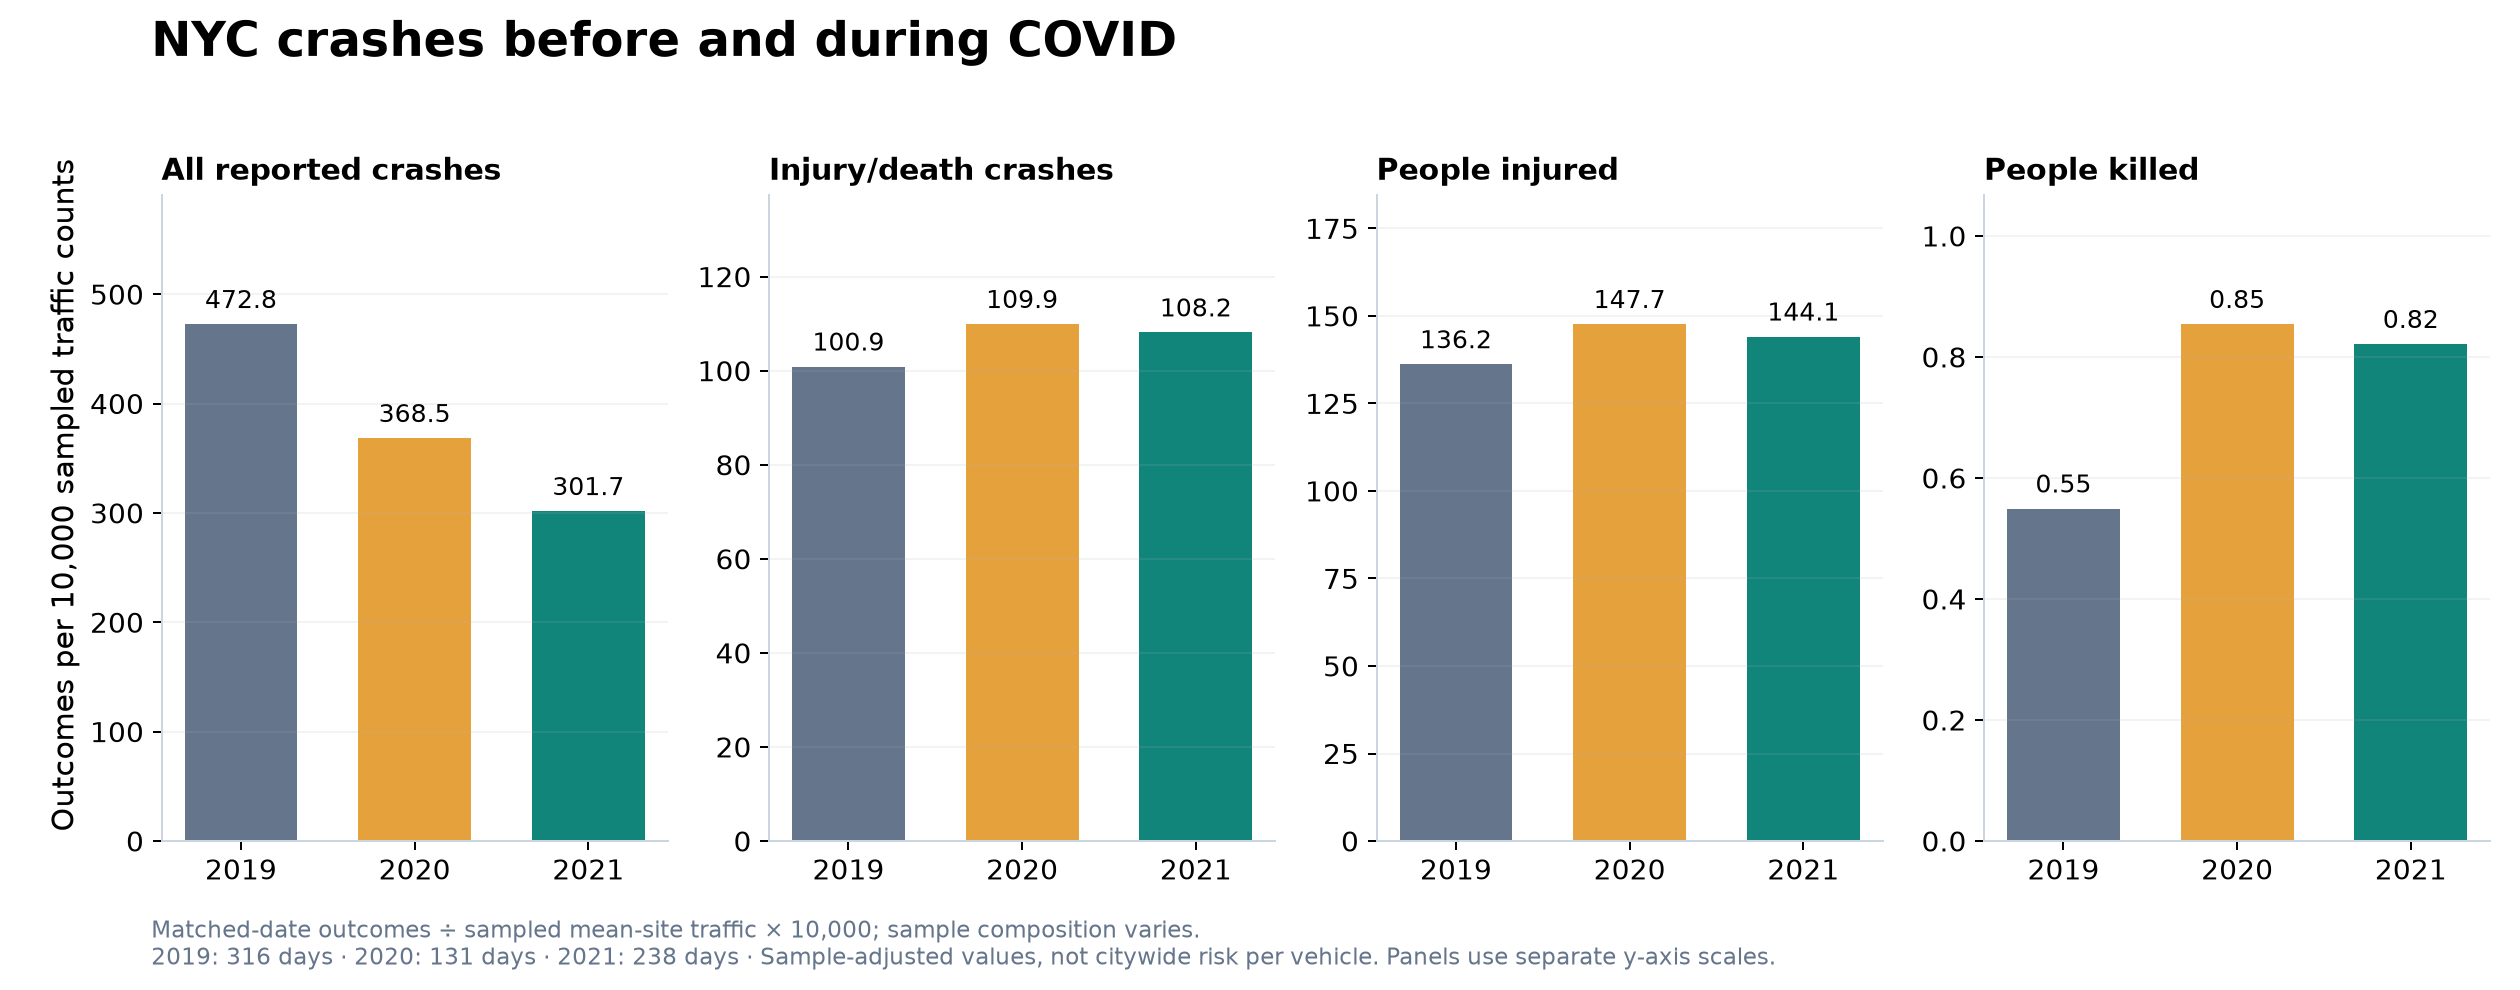

In [2]:
metrics = ['crashes', 'harm_crashes', 'injured', 'killed']
labels = ['All reported\ncrashes', 'Injury/death\ncrashes', 'People\ninjured', 'People\nkilled']
annual = observed.groupby(observed.index.year)[metrics + ['mean_site_daily_count']].sum()
annual['matched_days'] = observed.groupby(observed.index.year).size()
annual['mean_sites'] = observed.groupby(observed.index.year).sampled_locations.mean()
rates = annual[metrics].div(annual.mean_site_daily_count, axis=0).mul(10000)
rates.loc[[2019, 2020, 2021]].to_csv(OUT / 'data/covid_normalized_values.csv')
annual.loc[[2019, 2020, 2021]].to_csv(OUT / 'data/covid_matched_counts_and_traffic.csv')
fig, axes = plt.subplots(1, 4, figsize=(14, 5.5))
for ax, metric, label in zip(axes, metrics, labels):
    values = rates.loc[[2019, 2020, 2021], metric].to_numpy()
    bars = ax.bar(range(3), values, color=[GRAY, ORANGE, TEAL], width=.65)
    ax.bar_label(bars, fmt='%.2f' if metric == 'killed' else '%.1f', padding=4, fontsize=10)
    ax.set_xticks(range(3), ['2019', '2020', '2021'])
    ax.set_ylim(0, values.max() * 1.25)
    ax.set_title(label.replace('\n', ' '), loc='left', fontsize=12)
    ax.grid(axis='y', alpha=.15)
fig.supylabel('Outcomes per 10,000 sampled traffic counts', fontsize=12)
fig.suptitle('NYC crashes before and during COVID', x=.06, ha='left', fontsize=19, fontweight='bold')
days = ' · '.join(f'{y}: {int(annual.loc[y, "matched_days"])} days' for y in [2019, 2020, 2021])
save_graph(fig, '01_covid_normalized_comparison',
           f'Matched-date outcomes ÷ sampled mean-site traffic × 10,000; sample composition varies.\n{days} · Sample-adjusted values, not citywide risk per vehicle. Panels use separate y-axis scales.')

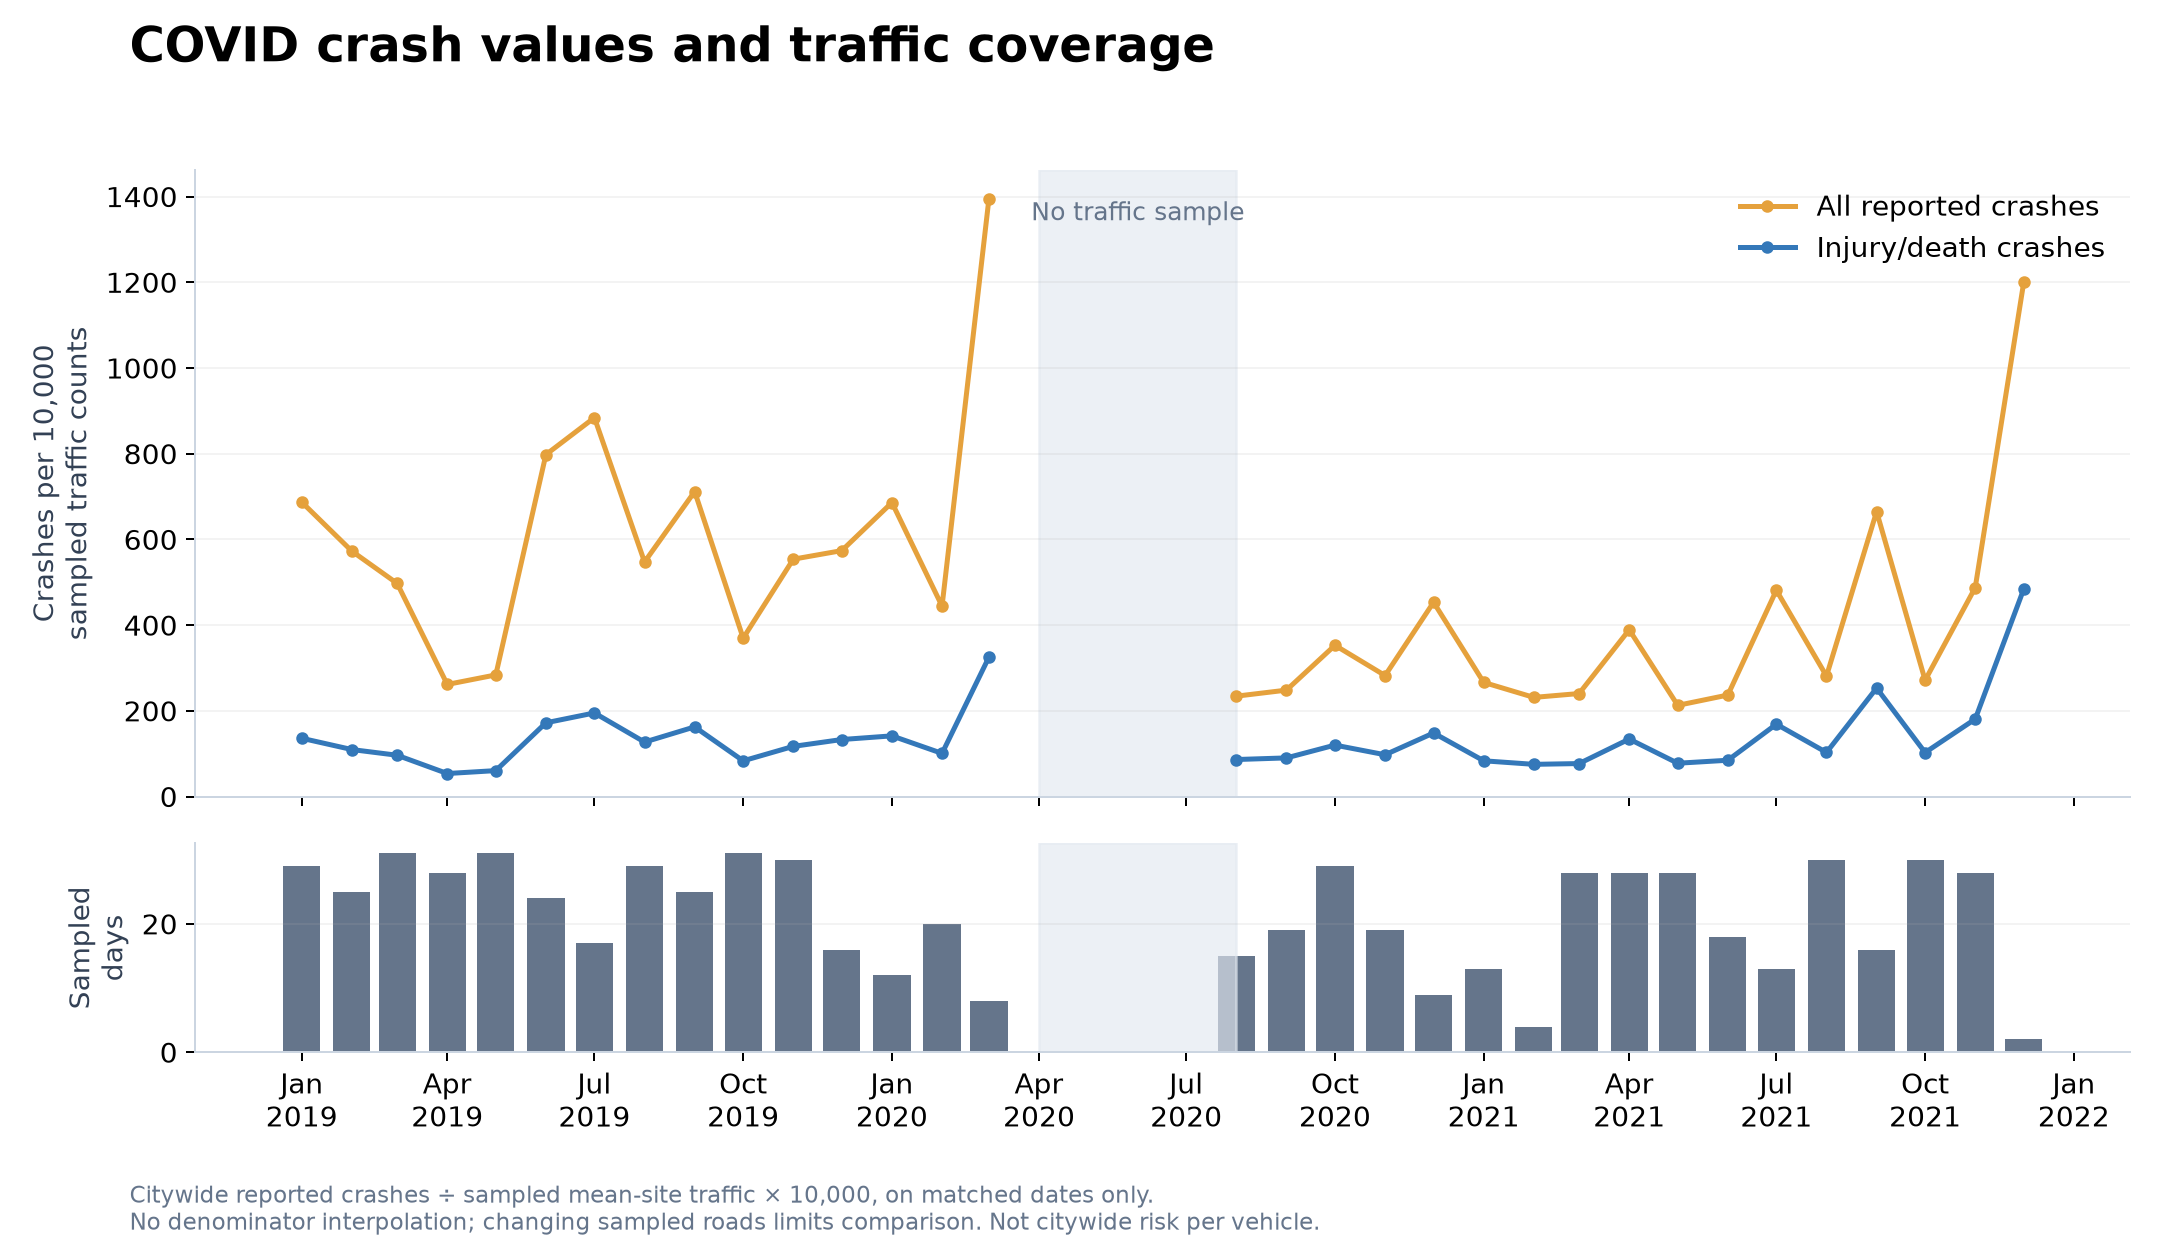

In [3]:
window = traffic.loc['2019-01-01':'2021-12-31']
month_index = pd.date_range('2019-01-01', '2021-12-01', freq='MS')
matched = observed.loc['2019-01-01':'2021-12-31']
mo = matched.resample('MS')[metrics + ['mean_site_daily_count']].sum(min_count=1).reindex(month_index)
mo['sampled_days'] = matched.resample('MS').size().reindex(month_index, fill_value=0)
monthly_rates = mo[metrics].div(mo.mean_site_daily_count, axis=0).mul(10000)
monthly_rates.to_csv(OUT / 'data/covid_monthly_normalized_values.csv')
mo.to_csv(OUT / 'data/covid_monthly_coverage.csv')
assert mo.loc['2020-04-01':'2020-07-01', 'sampled_days'].eq(0).all()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for metric, label, color in [('crashes', 'All reported crashes', ORANGE), ('harm_crashes', 'Injury/death crashes', BLUE)]:
    axes[0].plot(monthly_rates.index, monthly_rates[metric], 'o-', color=color, lw=2, ms=4, label=label)
axes[0].set_ylabel('Crashes per 10,000\nsampled traffic counts')
axes[0].set_ylim(bottom=0)
axes[0].legend(frameon=False)
axes[1].bar(mo.index, mo.sampled_days, width=23, color=GRAY)
axes[1].set_ylabel('Sampled\ndays')
for ax in axes:
    ax.axvspan(pd.Timestamp('2020-04-01'), pd.Timestamp('2020-08-01'), color='#e2e8f0', alpha=.65)
    ax.grid(axis='y', alpha=.15)
axes[0].text(pd.Timestamp('2020-06-01'), .95, 'No traffic sample', ha='center', va='top',
             transform=axes[0].get_xaxis_transform(), color=GRAY, fontsize=10)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
fig.suptitle('COVID crash values and traffic coverage', fontsize=19, fontweight='bold', x=.06, ha='left')
save_graph(fig, '02_covid_monthly_values_and_coverage', 'Citywide reported crashes ÷ sampled mean-site traffic × 10,000, on matched dates only.\nNo denominator interpolation; changing sampled roads limits comparison. Not citywide risk per vehicle.')
for obsolete in [GRAPHS / '02_covid_monthly_indices_and_coverage.png',
                 OUT / 'data/covid_normalized_indices.csv', OUT / 'data/covid_monthly_normalized_indices.csv']:
    if obsolete.exists():
        obsolete.unlink()

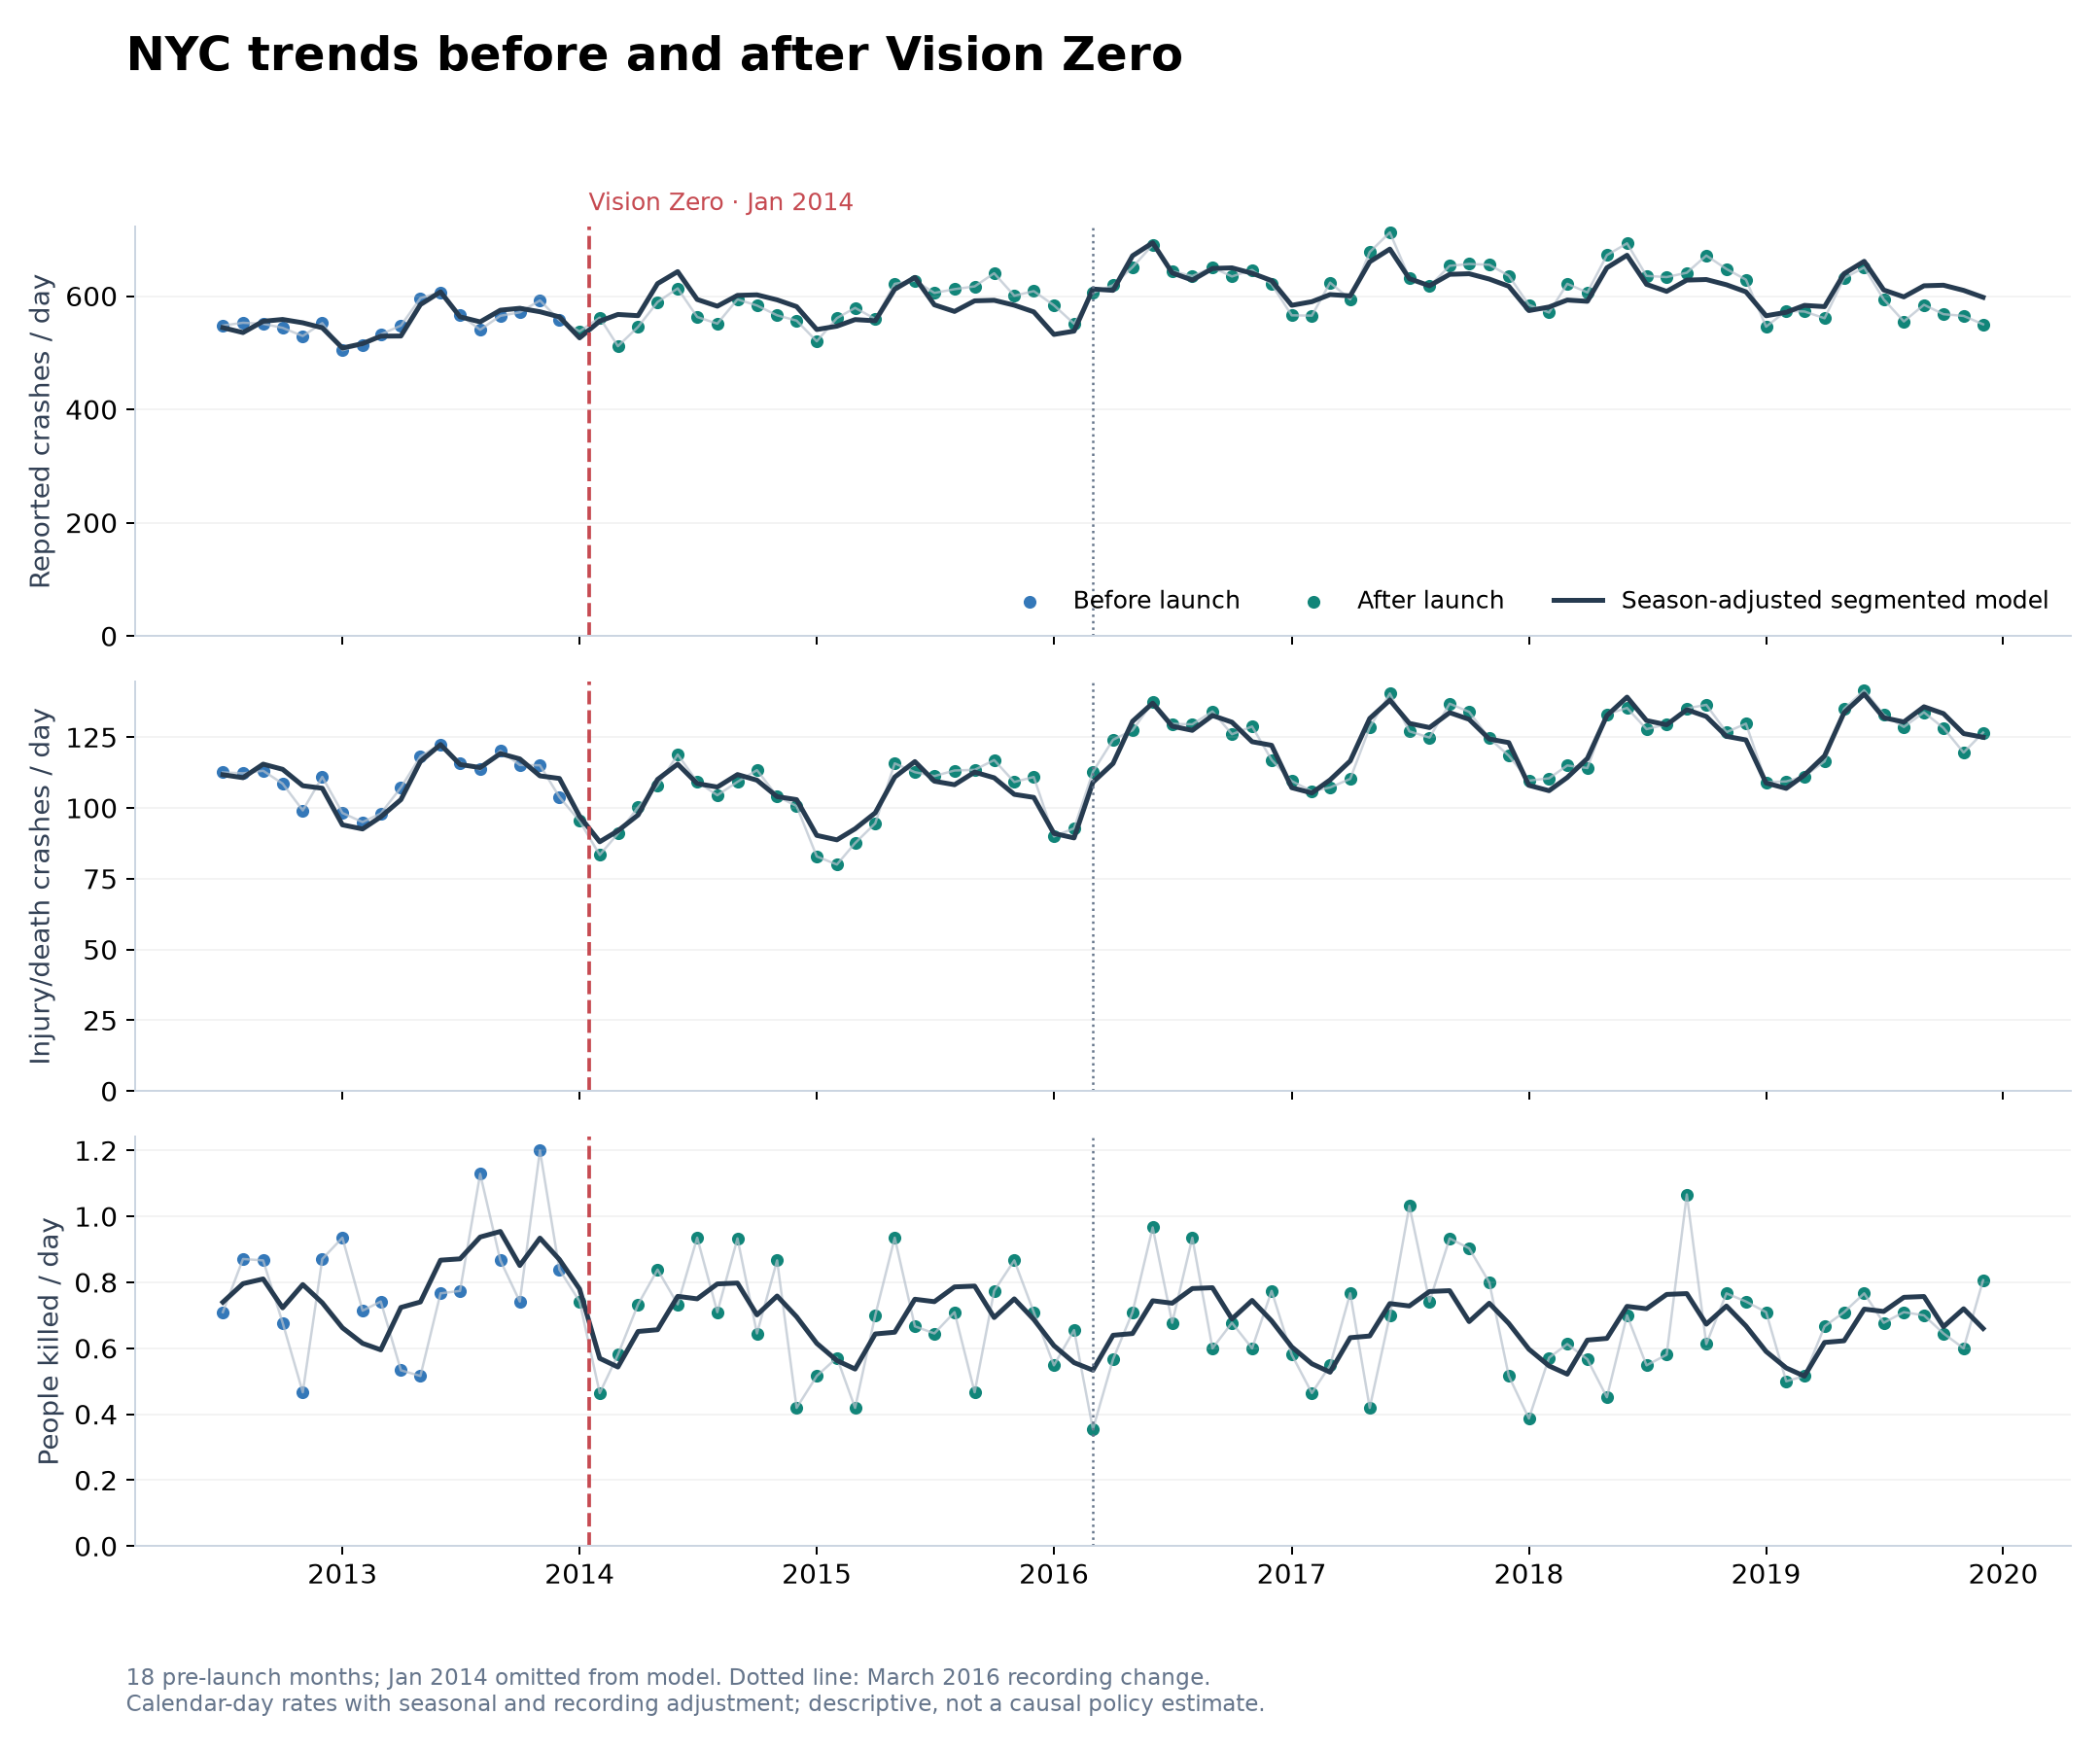

In [4]:
vz = monthly.loc['2012-07-01':'2019-12-01'].copy()
vz['t'] = np.arange(len(vz))
event_t = int(vz.loc['2014-02-01', 't'])
vz['post'] = (vz.index >= '2014-02-01').astype(int)
vz['after_t'] = np.maximum(vz.t - event_t, 0)
vz['recording'] = (vz.index >= '2016-03-01').astype(int)
fit_data = vz.loc[vz.index != '2014-01-01']
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
model_rows = []
for ax, metric, label in zip(axes, ['crashes', 'harm_crashes', 'killed'], ['Reported crashes / day', 'Injury/death crashes / day', 'People killed / day']):
    model = smf.glm(f'{metric} ~ t + C(month_of_year) + post + after_t + recording', data=fit_data,
                    family=sm.families.Poisson(), offset=np.log(fit_data.calendar_days)).fit(
                        cov_type='HAC', cov_kwds={'maxlags': 12})
    observed_rate = vz[metric] / vz.calendar_days
    pre = vz.index < '2014-01-01'
    ax.plot(vz.index, observed_rate, color='#b7c1cd', lw=1, alpha=.7)
    ax.scatter(vz.index[pre], observed_rate[pre], color=BLUE, s=18, label='Before launch')
    ax.scatter(vz.index[~pre], observed_rate[~pre], color=TEAL, s=18, label='After launch')
    prediction = model.predict(vz, offset=np.log(vz.calendar_days)) / vz.calendar_days
    ax.plot(vz.index, prediction, color='#263b50', lw=2, label='Season-adjusted segmented model')
    ax.axvline(pd.Timestamp('2014-01-15'), color=RED, ls='--', lw=1.5)
    ax.axvline(pd.Timestamp('2016-03-01'), color=GRAY, ls=':', lw=1)
    ax.set_ylabel(label)
    ax.grid(axis='y', alpha=.15)
    ax.set_ylim(bottom=0)
    model_rows.append({'outcome': metric, 'pre_monthly_trend_percent': 100 * np.expm1(model.params['t']),
                       'post_monthly_trend_percent': 100 * np.expm1(model.params['t'] + model.params['after_t']),
                       'post_level_percent': 100 * np.expm1(model.params['post']), 'pre_months': int((fit_data.post == 0).sum())})
axes[0].legend(frameon=False, ncol=3, fontsize=10)
axes[0].text(pd.Timestamp('2014-01-15'), 1.04, 'Vision Zero · Jan 2014', transform=axes[0].get_xaxis_transform(), color=RED, fontsize=10)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('NYC trends before and after Vision Zero', x=.06, ha='left', fontsize=19, fontweight='bold')
pd.DataFrame(model_rows).to_csv(OUT / 'data/vision_zero_trends.csv', index=False)
save_graph(fig, '03_vision_zero_before_after_trends', '18 pre-launch months; Jan 2014 omitted from model. Dotted line: March 2016 recording change.\nCalendar-day rates with seasonal and recording adjustment; descriptive, not a causal policy estimate.')

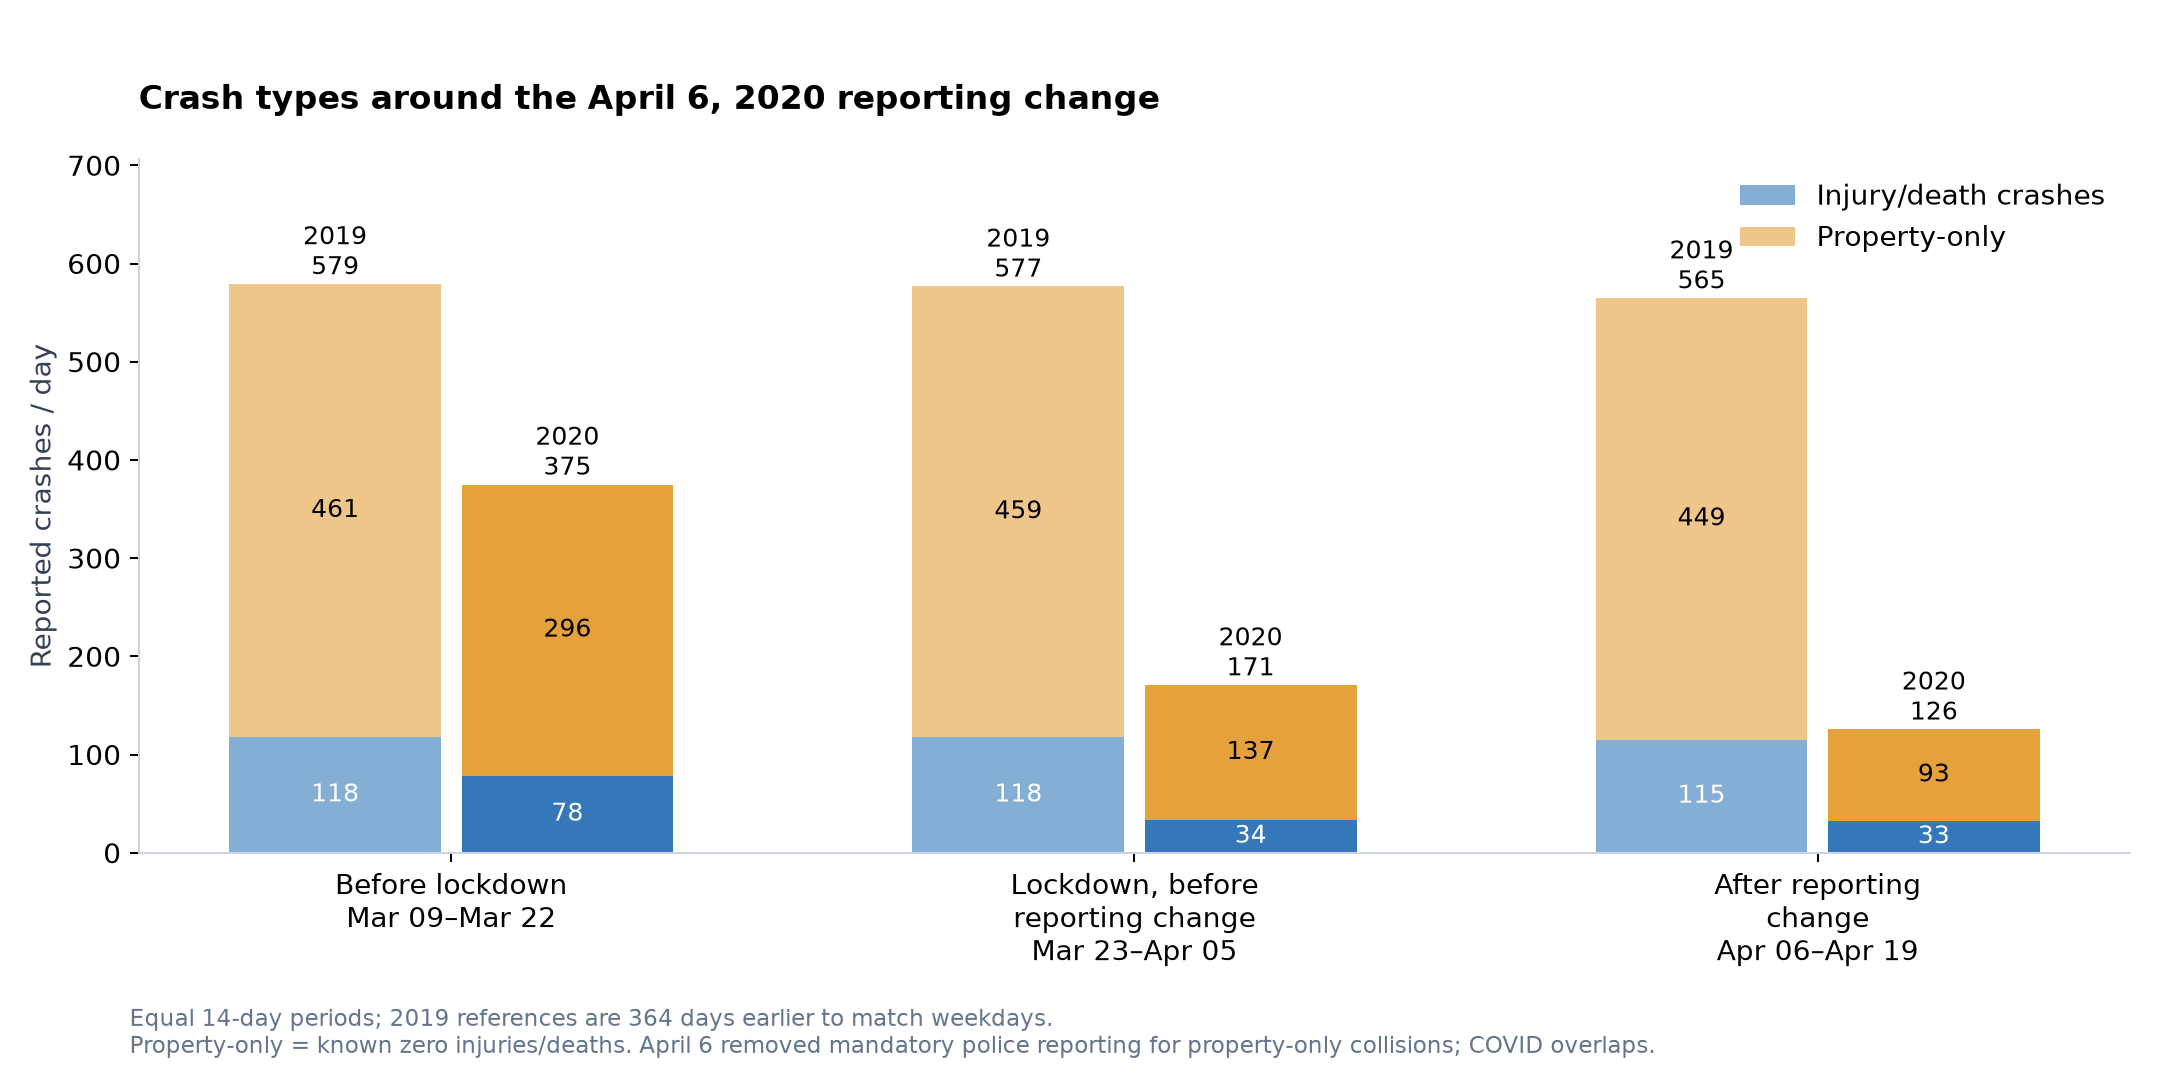

In [5]:
stages = [('Before lockdown', '2020-03-09', '2020-03-22'),
          ('Lockdown, before\nreporting change', '2020-03-23', '2020-04-05'),
          ('After reporting\nchange', '2020-04-06', '2020-04-19')]
report_rows = []
for stage, start, end in stages:
    dates = pd.date_range(start, end)
    for year, shift in [(2019, 364), (2020, 0)]:
        sample = daily.loc[dates - pd.Timedelta(days=shift)]
        row = {'stage': stage.replace('\n', ' '), 'year': year, 'days': len(sample),
               'harm_daily': sample.harm_crashes.mean(), 'property_proxy_daily': sample.non_harm_crashes.mean(),
               'unknown_daily': (sample.crashes - sample.known_harm).mean()}
        report_rows.append(row)
report_table = pd.DataFrame(report_rows)
report_table.to_csv(OUT / 'data/reporting_change_period_rates.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 6))
for j, year in enumerate([2019, 2020]):
    sub = report_table.loc[report_table.year.eq(year)]
    positions = np.arange(3) + (j - .5) * .34
    injury = ax.bar(positions, sub.harm_daily, width=.31, color=BLUE, alpha=.6 if year == 2019 else 1,
                    label='Injury/death crashes' if j == 0 else None)
    property_bars = ax.bar(positions, sub.property_proxy_daily, bottom=sub.harm_daily, width=.31,
                          color=ORANGE, alpha=.6 if year == 2019 else 1, label='Property-only' if j == 0 else None)
    bottom = sub.harm_daily + sub.property_proxy_daily
    if sub.unknown_daily.sum():
        ax.bar(positions, sub.unknown_daily, bottom=bottom, width=.31, color=GRAY, label='Unknown harm' if j == 0 else None)
    for pos, total, h, p in zip(positions, bottom + sub.unknown_daily, sub.harm_daily, sub.property_proxy_daily):
        ax.text(pos, total + 10, f'{year}\n{total:.0f}', ha='center', fontsize=10)
        ax.text(pos, h / 2, f'{h:.0f}', ha='center', va='center', fontsize=10, color='white')
        ax.text(pos, h + p / 2, f'{p:.0f}', ha='center', va='center', fontsize=10)
ax.set_xticks(range(3), [s[0] + '\n' + pd.Timestamp(s[1]).strftime('%b %d') + '–' + pd.Timestamp(s[2]).strftime('%b %d') for s in stages])
ax.set_ylabel('Reported crashes / day')
ax.set_ylim(0, (report_table.harm_daily + report_table.property_proxy_daily + report_table.unknown_daily).max() * 1.22)
ax.set_title('Crash types around the April 6, 2020 reporting change', loc='left', pad=20)
ax.legend(frameon=False, loc='upper right')
save_graph(fig, '04_reporting_change_stacked_rates', 'Equal 14-day periods; 2019 references are 364 days earlier to match weekdays.\nProperty-only = known zero injuries/deaths. April 6 removed mandatory police reporting for property-only collisions; COVID overlaps.')

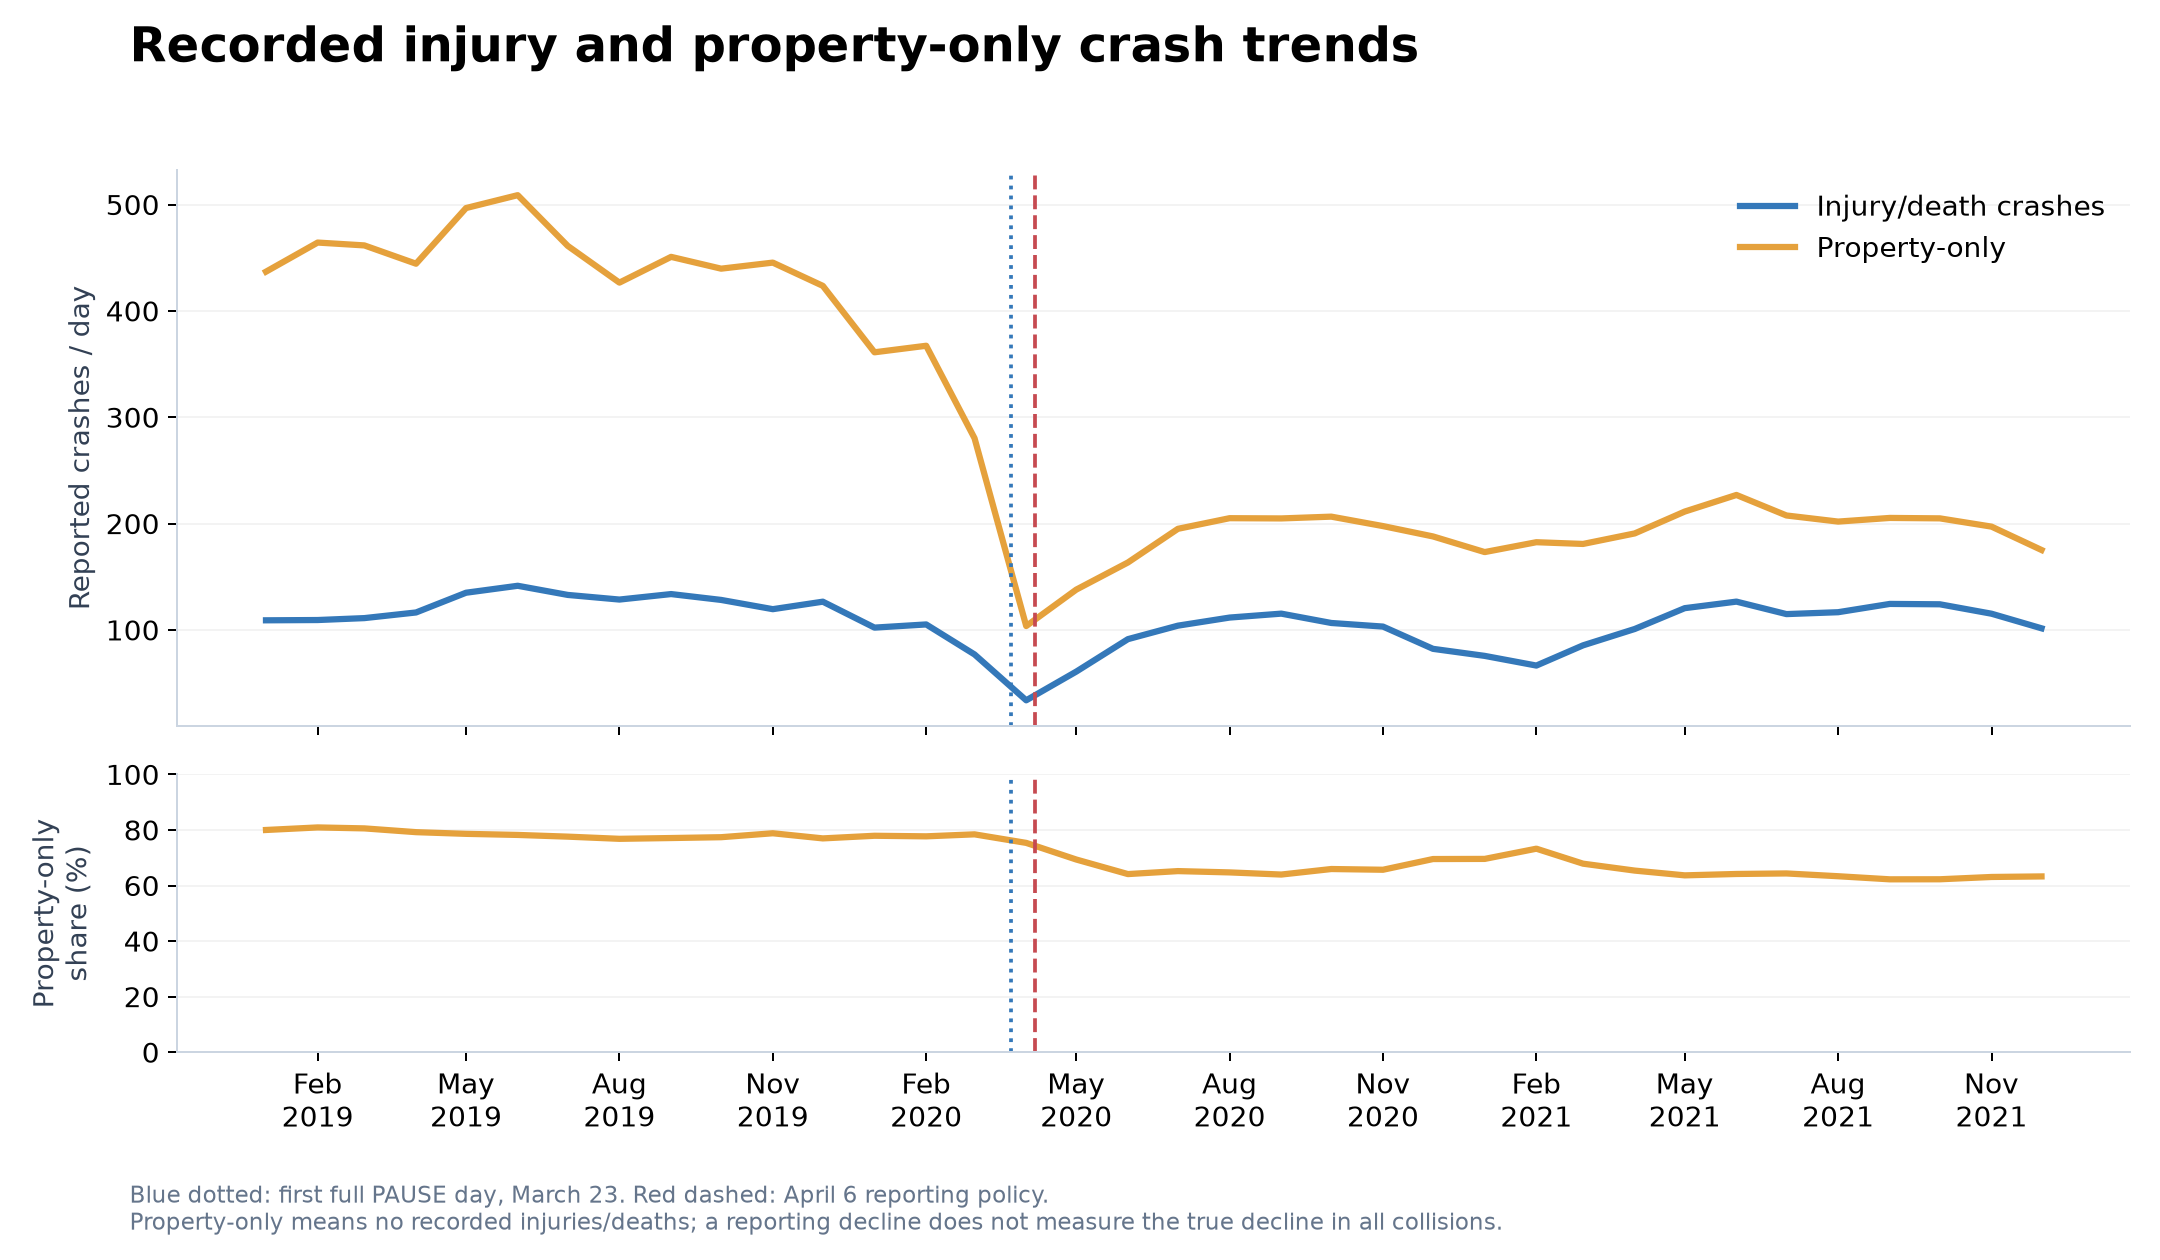

In [6]:
report_daily = daily.loc['2019-01-01':'2021-12-31'].copy()
report_monthly = report_daily.resample('MS')[['harm_crashes', 'non_harm_crashes', 'known_harm']].sum()
report_monthly['days'] = report_daily.resample('MS').size()
report_monthly.to_csv(OUT / 'data/reporting_monthly_counts.csv')
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for metric, label, color in [('harm_crashes', 'Injury/death crashes', BLUE), ('non_harm_crashes', 'Property-only', ORANGE)]:
    axes[0].plot(report_monthly.index, report_monthly[metric] / report_monthly.days, color=color, lw=2.5, label=label)
share = 100 * report_monthly.non_harm_crashes / report_monthly.known_harm
axes[1].plot(share.index, share, color=ORANGE, lw=2.5)
axes[0].set_ylabel('Reported crashes / day')
axes[1].set_ylabel('Property-only\nshare (%)')
axes[1].set_ylim(0, 100)
axes[0].legend(frameon=False)
for ax in axes:
    ax.axvline(pd.Timestamp('2020-03-23'), color=BLUE, ls=':', lw=1.5)
    ax.axvline(pd.Timestamp('2020-04-06'), color=RED, ls='--', lw=1.5)
    ax.grid(axis='y', alpha=.15)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
fig.suptitle('Recorded injury and property-only crash trends', x=.06, ha='left', fontsize=19, fontweight='bold')
save_graph(fig, '05_reporting_change_monthly_trends', 'Blue dotted: first full PAUSE day, March 23. Red dashed: April 6 reporting policy.\nProperty-only means no recorded injuries/deaths; a reporting decline does not measure the true decline in all collisions.')

In [7]:
roads = json.loads((OUT / 'data/street_centerlines.json').read_text())
def road_lines(name=None):
    return [np.asarray(line, float) for road in roads if name is None or road.get('full_street_name') == name
            for line in road['the_geom']['coordinates']]

scale = np.array([111320 * np.cos(np.deg2rad(40.754)), 111320])
avenue_nodes = np.concatenate(road_lines('34 AVE'))
endpoints = []
for name in ['69 ST', 'JUNCTION BLVD']:
    cross_nodes = np.concatenate(road_lines(name))
    distances = np.linalg.norm((avenue_nodes[:, None, :] - cross_nodes[None, :, :]) * scale, axis=2).min(axis=1)
    shared = np.unique(avenue_nodes[distances < 3], axis=0)
    assert len(shared) > 0
    endpoints.append(shared.mean(axis=0))
west, east = endpoints
corridor_lines = [line for line in road_lines('34 AVE') if west[0] <= line[:, 0].mean() <= east[0]]
assert len(corridor_lines) > 30
segments = np.concatenate([np.stack([line[:-1], line[1:]], axis=1) for line in corridor_lines])
origin = west
a, b = (segments[:, 0] - origin) * scale, (segments[:, 1] - origin) * scale
ab = b - a

def distance_to_corridor(points):
    p = (points - origin) * scale
    t = np.clip(np.sum((p[:, None, :] - a) * ab, axis=2) / np.sum(ab * ab, axis=1), 0, 1)
    return np.linalg.norm(p[:, None, :] - (a + t[:, :, None] * ab), axis=2).min(axis=1)

def clean_street(series):
    return (series.fillna('').str.upper().str.strip().str.replace(r'\s+', ' ', regex=True)
            .str.replace(r'\b(\d+)(?:ST|ND|RD|TH)\b', r'\1', regex=True)
            .str.replace(r'\bAVENUE\b', 'AVE', regex=True).str.replace(r'\bSTREET\b', 'ST', regex=True)
            .str.replace(r'\bBOULEVARD\b', 'BLVD', regex=True))

street_parts = []
street_audit = {'named_corridor_candidates': 0, 'spatial_outliers': 0, 'missing_coordinates_retained': 0}
columns = ['COLLISION_ID', 'CRASH DATE', 'BOROUGH', 'LATITUDE', 'LONGITUDE', 'ON STREET NAME',
           'CROSS STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED',
           'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF CYCLIST INJURED']
for chunk in pd.read_csv(ROOT / 'data/motor_vehicle_collisions.csv', usecols=columns, chunksize=200000):
    on, cross = clean_street(chunk['ON STREET NAME']), clean_street(chunk['CROSS STREET NAME'])
    named = on.eq('34 AVE') | cross.eq('34 AVE')
    cross_number = cross.str.extract(r'^(\d+) ST$')[0].astype(float)
    on_number = on.str.extract(r'^(\d+) ST$')[0].astype(float)
    bounded_name = ((on.eq('34 AVE') & (cross_number.between(69, 94) | cross.eq('JUNCTION BLVD'))) |
                    (cross.eq('34 AVE') & (on_number.between(69, 94) | on.eq('JUNCTION BLVD'))))
    lat = pd.to_numeric(chunk.LATITUDE, errors='coerce')
    lon = pd.to_numeric(chunk.LONGITUDE, errors='coerce')
    usable = lat.between(40.49, 40.92) & lon.between(-74.26, -73.68)
    local = usable & lon.between(west[0] - .00035, east[0] + .00035) & lat.between(west[1] - .0005, east[1] + .0005)
    distance = pd.Series(np.inf, index=chunk.index)
    mask = local & named
    if mask.any():
        distance.loc[mask] = distance_to_corridor(np.column_stack([lon[mask], lat[mask]]))
    keep = named & ((local & distance.le(35)) | (~usable & bounded_name & chunk.BOROUGH.eq('QUEENS')))
    street_audit['named_corridor_candidates'] += int((named & bounded_name).sum())
    street_audit['spatial_outliers'] += int((named & bounded_name & usable & ~keep).sum())
    street_audit['missing_coordinates_retained'] += int((keep & ~usable).sum())
    sub = chunk.loc[keep].copy()
    sub['date'] = pd.to_datetime(sub['CRASH DATE'], format='%m/%d/%Y', errors='coerce')
    sub['lon'], sub['lat'], sub['mapped'] = lon[keep], lat[keep], usable[keep]
    for original, short in [('NUMBER OF PERSONS INJURED', 'injured'), ('NUMBER OF PERSONS KILLED', 'killed'),
                            ('NUMBER OF PEDESTRIANS INJURED', 'ped_injured'), ('NUMBER OF CYCLIST INJURED', 'cyclist_injured')]:
        sub[short] = pd.to_numeric(sub[original], errors='coerce')
    known = sub.injured.notna() & sub.killed.notna()
    sub['harm_crashes'] = (sub.injured.gt(0) | sub.killed.gt(0)).astype(float).where(known)
    sub['property_proxy'] = (sub.injured.eq(0) & sub.killed.eq(0)).astype(float).where(known)
    sub['crashes'] = 1
    street_parts.append(sub[['COLLISION_ID', 'date', 'lon', 'lat', 'mapped', 'crashes', 'harm_crashes', 'property_proxy',
                             'injured', 'killed', 'ped_injured', 'cyclist_injured']])
street = pd.concat(street_parts, ignore_index=True).dropna(subset=['date']).sort_values('date')
assert street.COLLISION_ID.is_unique
assert len(street) > 100
street.to_csv(OUT / 'data/34ave_crashes.csv', index=False)
street_audit.update({'selected_crashes': len(street), 'mapped_crashes': int(street.mapped.sum()),
                    'unknown_harm_status': int(street.harm_crashes.isna().sum()),
                    'distance_m': 35, 'definition': 'Named 34 AVE on/cross street, within 35m of official corridor centerlines including intersections. Missing coordinates retained only with Queens and an explicit corridor cross street.',
                    'west_endpoint': west.tolist(), 'east_endpoint': east.tolist(),
                    'geometry_is_current_not_historical': True})
(OUT / 'data/34ave_selection_audit.json').write_text(json.dumps(street_audit, indent=2))

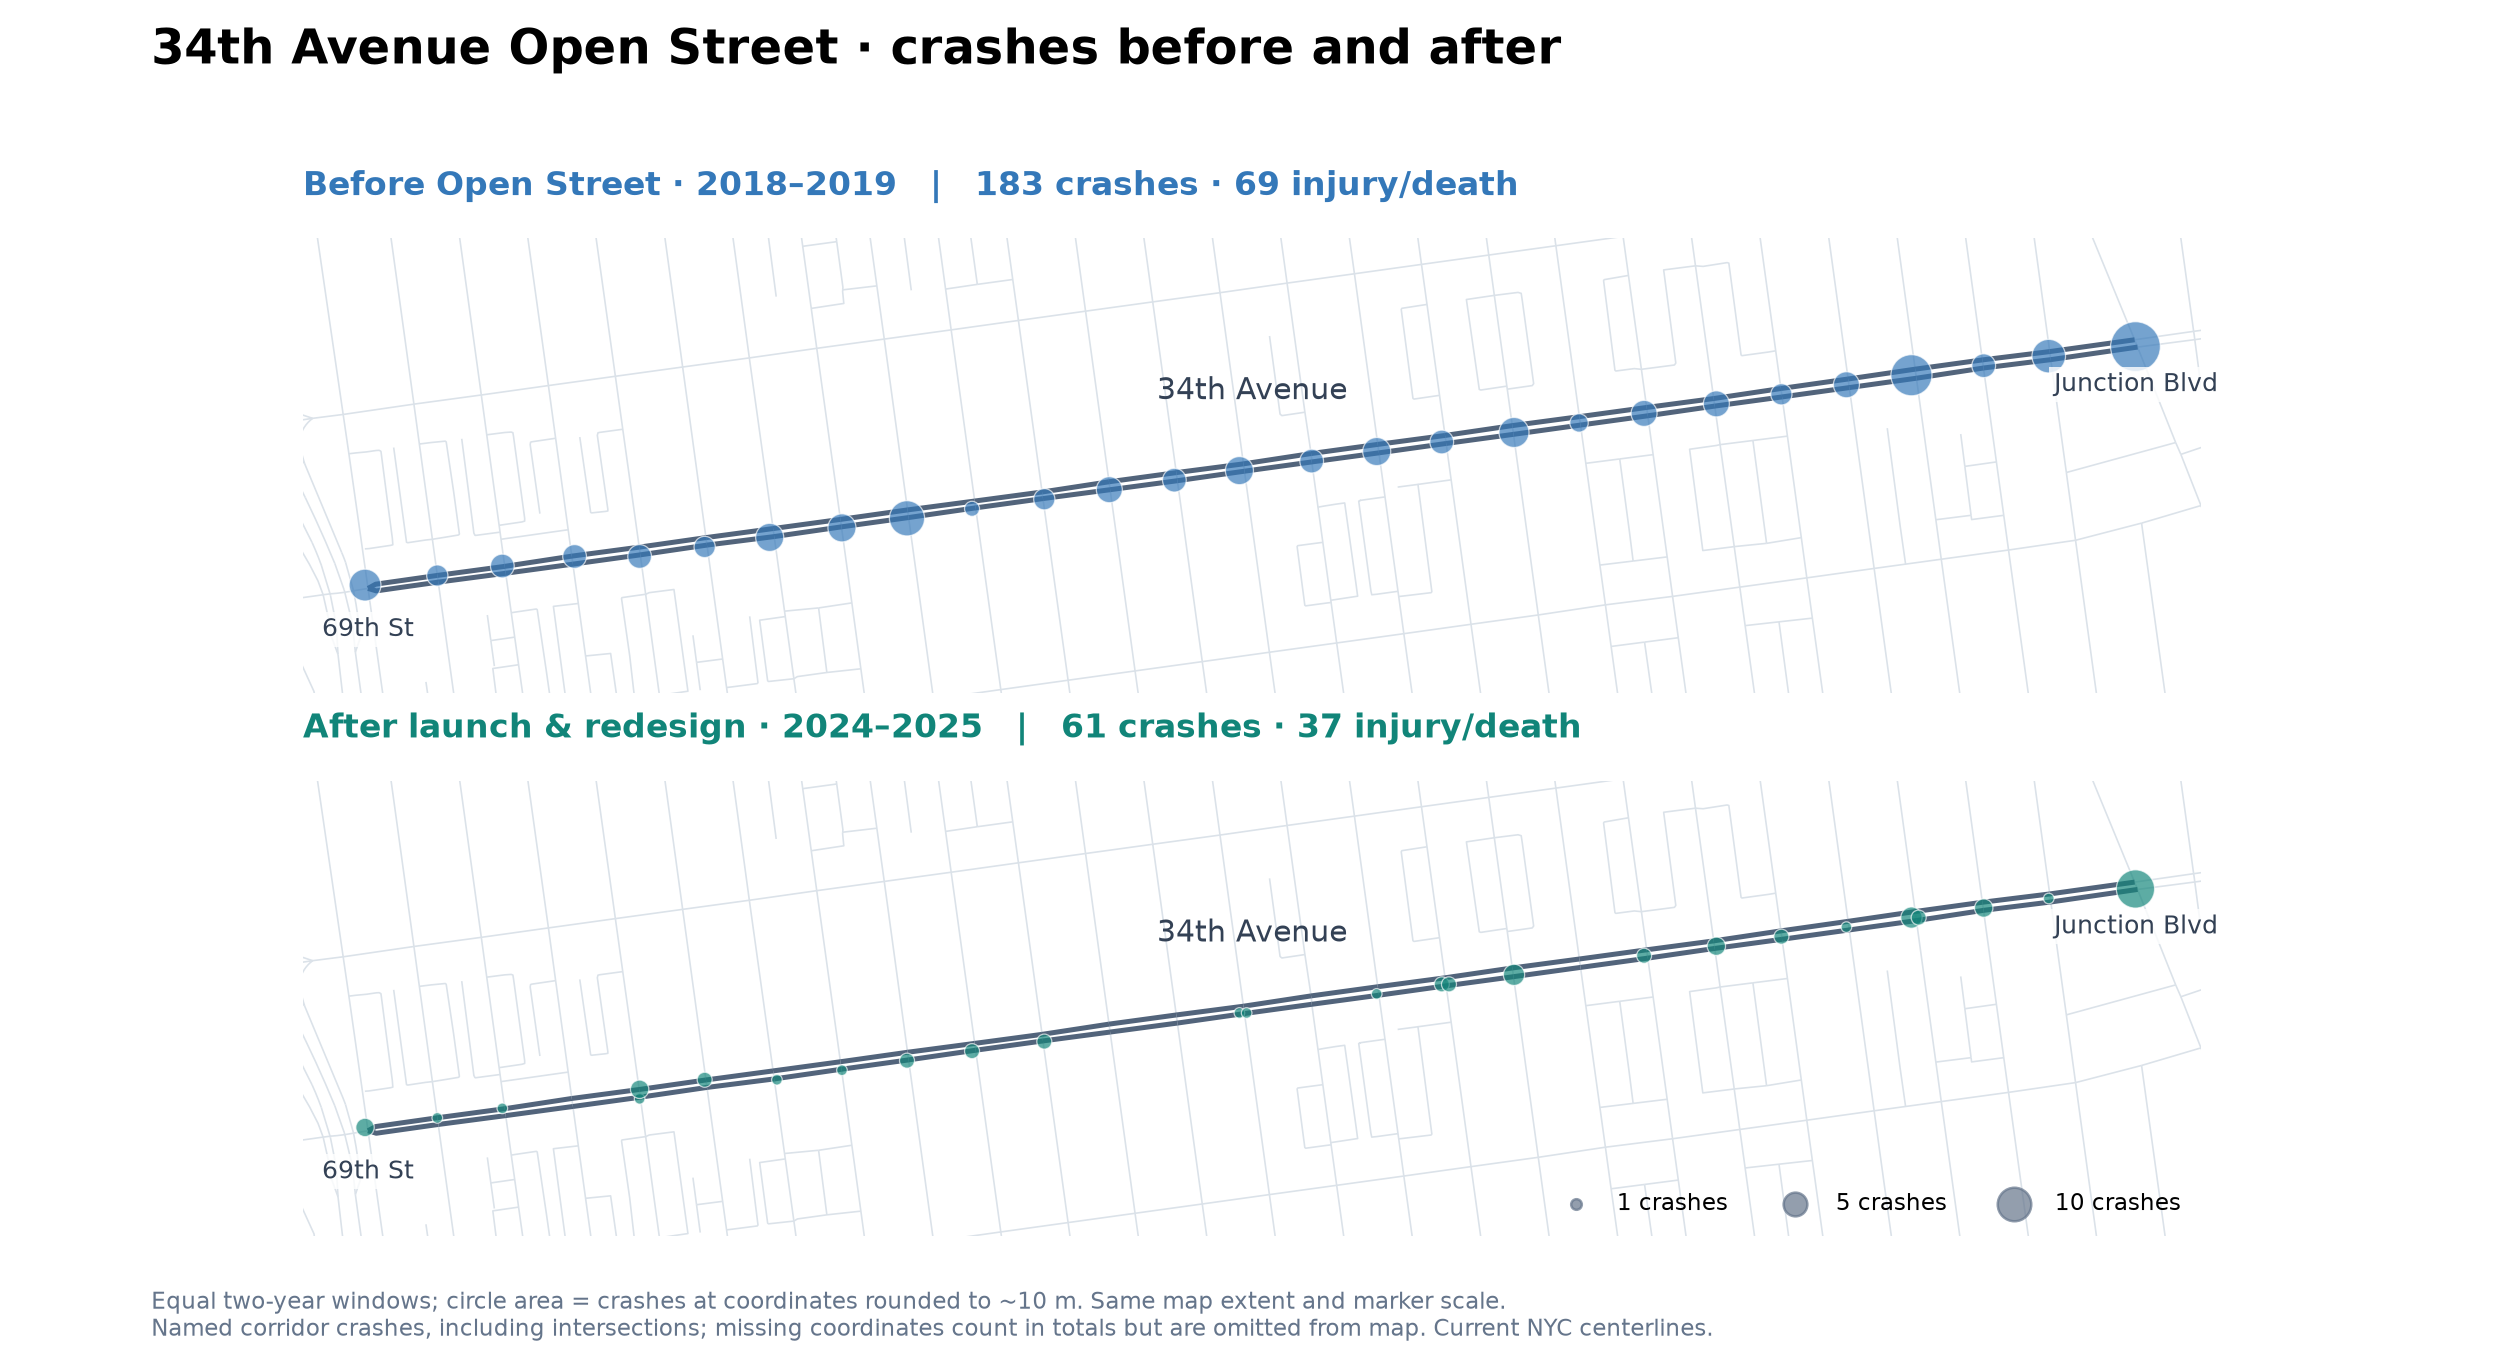

In [8]:
periods = [('Before Open Street · 2018–2019', '2018-01-01', '2019-12-31', BLUE),
           ('After launch & redesign · 2024–2025', '2024-01-01', '2025-12-31', TEAL)]
fig, axes = plt.subplots(2, 1, figsize=(14, 7.6), sharex=True, sharey=True)
all_road_lines = road_lines()
size_scale = 18
for ax, (label, start, end, color) in zip(axes, periods):
    sub = street.loc[street.date.between(start, end)]
    mapped = sub.loc[sub.mapped].copy()
    mapped['x'], mapped['y'] = mapped.lon.round(4), mapped.lat.round(4)
    points = mapped.groupby(['x', 'y']).size().reset_index(name='count')
    ax.add_collection(LineCollection(all_road_lines, colors='#dbe2e9', linewidths=.65, zorder=1))
    ax.add_collection(LineCollection(corridor_lines, colors='#52647b', linewidths=2, zorder=2))
    ax.scatter(points.x, points.y, s=points['count'] * size_scale, c=color, alpha=.68, edgecolors='white', linewidths=.5, zorder=3)
    ax.set_xlim(west[0] - .0009, east[0] + .0009)
    ax.set_ylim(west[1] - .0011, east[1] + .0011)
    ax.set_aspect(1 / np.cos(np.deg2rad(40.754)))
    ax.set_axis_off()
    ax.set_title(f'{label}   |   {len(sub):,} crashes · {int(sub.harm_crashes.sum()):,} injury/death', loc='left', fontsize=13, color=color)
    for point, text in [(west, '69th St'), (east, 'Junction Blvd')]:
        ax.text(point[0], point[1] - .0005, text, ha='center', fontsize=10, color='#334155', zorder=4,
                bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': .8, 'pad': 2})
    ax.text((west[0] + east[0]) / 2, (west[1] + east[1]) / 2 + .0007, '34th Avenue', ha='center', fontsize=12, color='#334155')
for n in [1, 5, 10]:
    axes[1].scatter([], [], s=n * size_scale, c=GRAY, alpha=.7, label=f'{n} crashes')
axes[1].legend(frameon=False, loc='lower right', ncol=3, fontsize=9)
fig.suptitle('34th Avenue Open Street · crashes before and after', x=.06, ha='left', fontsize=19, fontweight='bold')
save_graph(fig, '06_34ave_before_after_map', 'Equal two-year windows; circle area = crashes at coordinates rounded to ~10 m. Same map extent and marker scale.\nNamed corridor crashes, including intersections; missing coordinates count in totals but are omitted from map. Current NYC centerlines.')

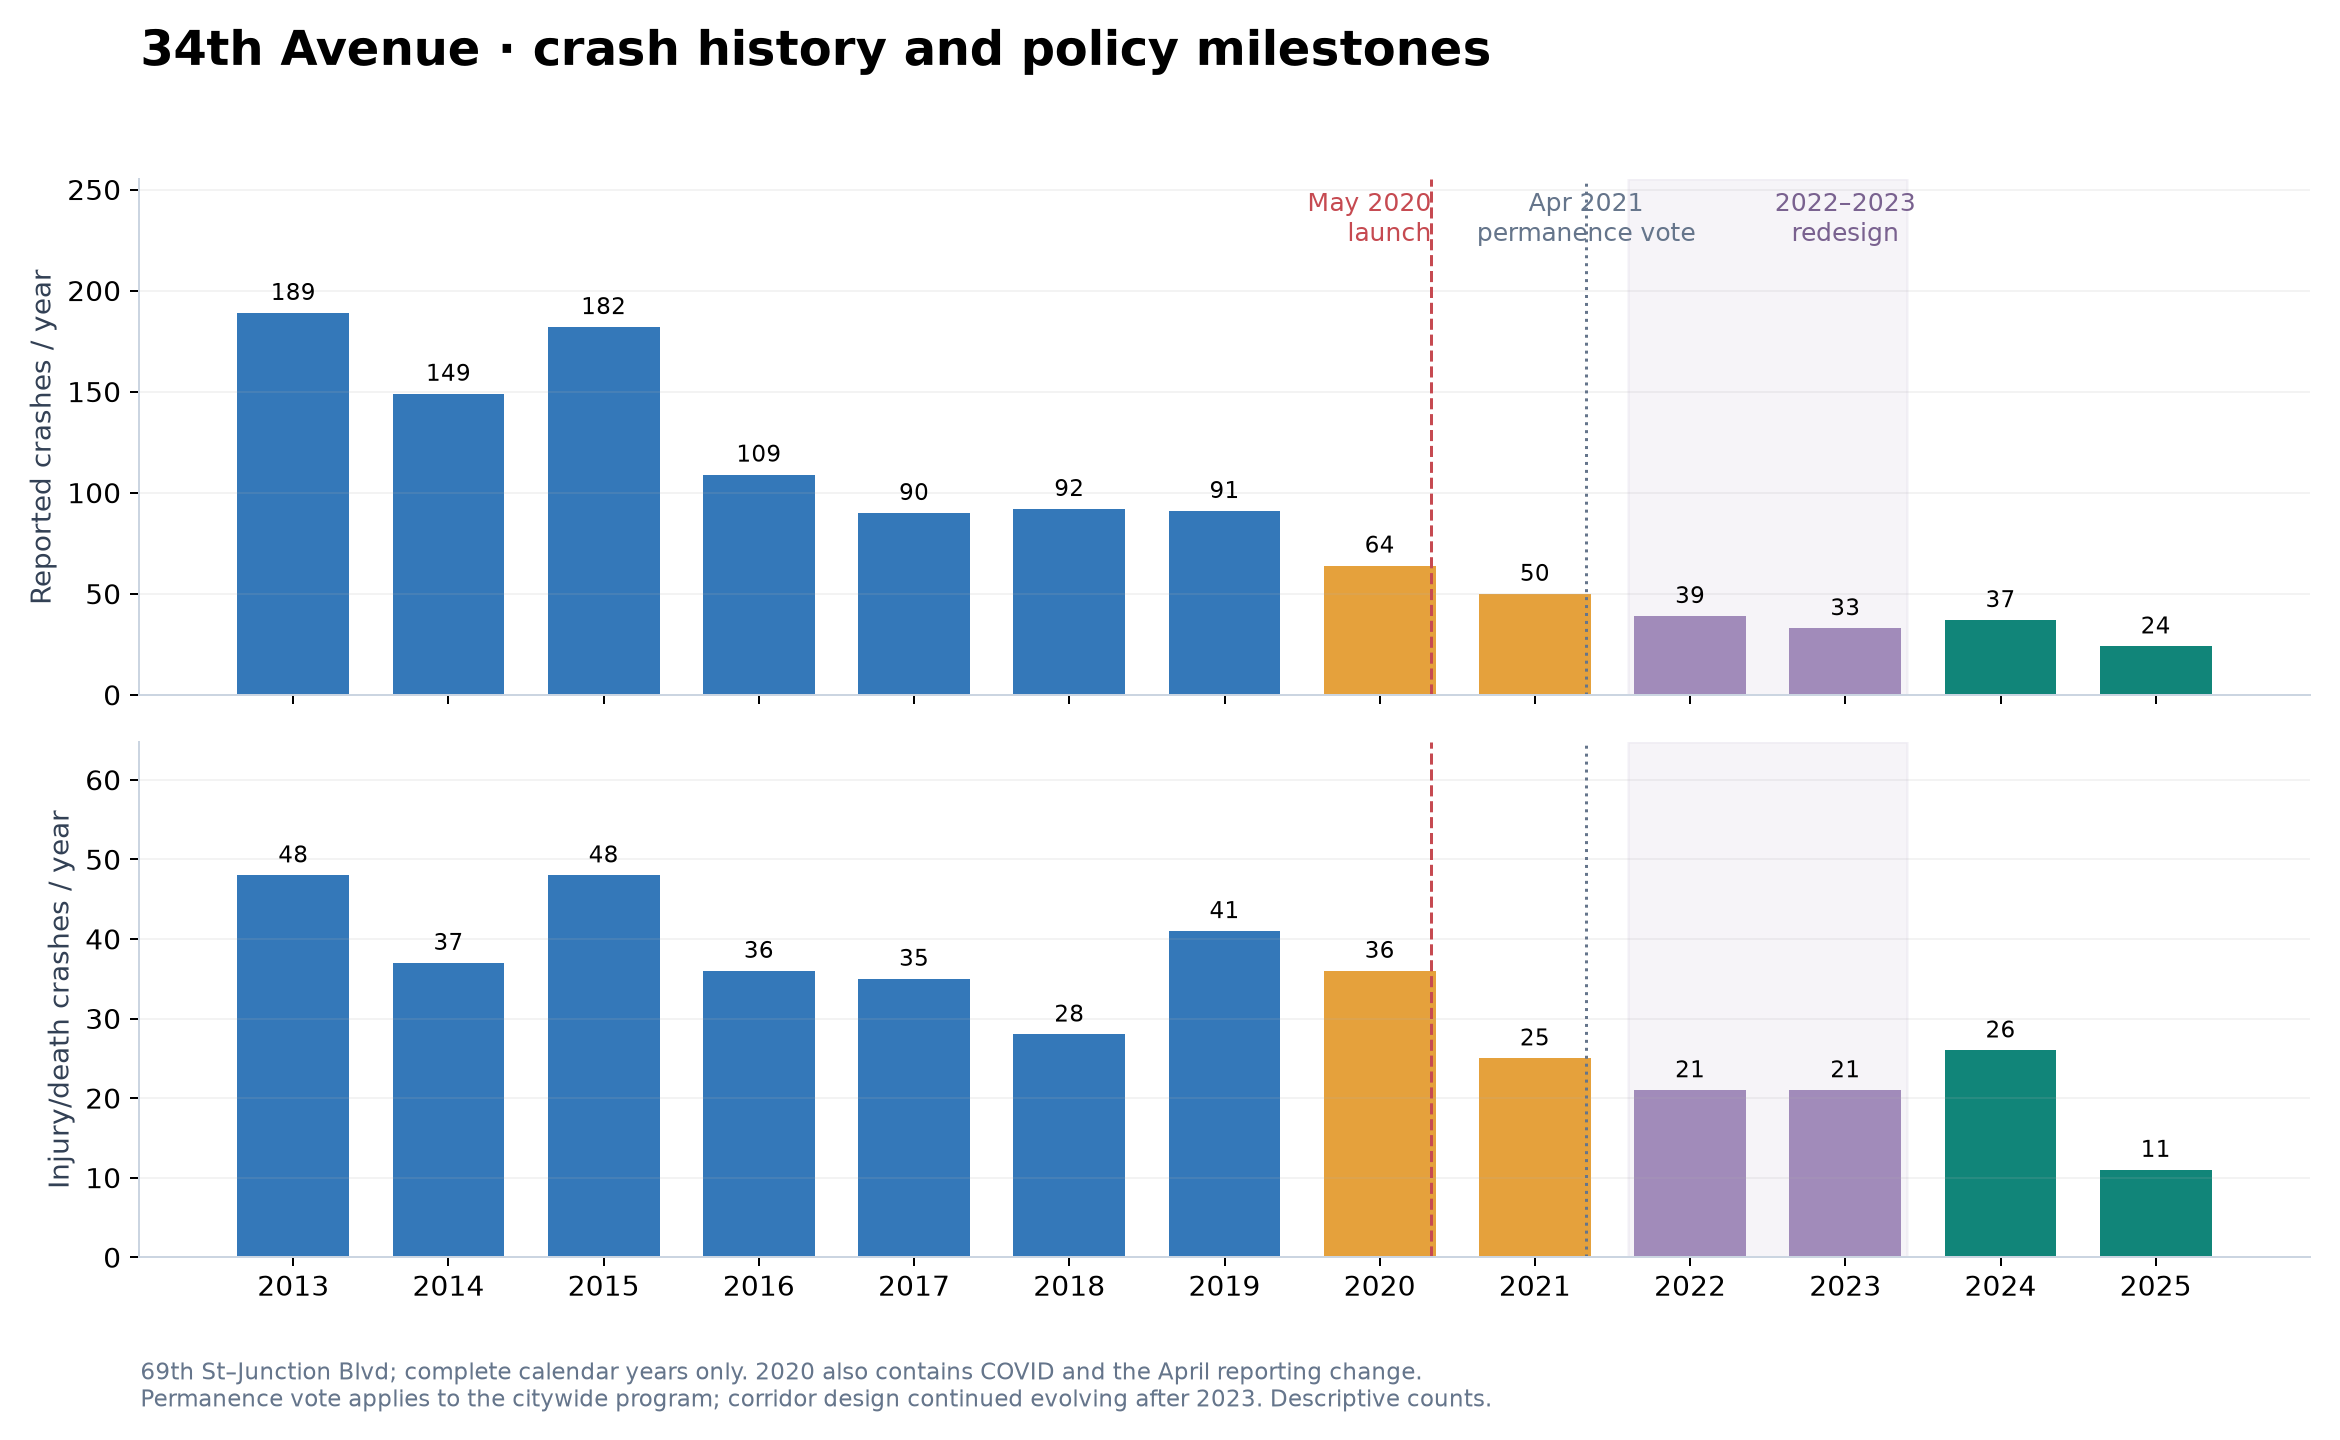

In [9]:
street_months = pd.date_range('2012-07-01', '2026-05-01', freq='MS')
street_m = street.set_index('date').resample('MS')[['crashes', 'harm_crashes', 'property_proxy', 'injured', 'killed', 'ped_injured', 'cyclist_injured']].sum(min_count=1).reindex(street_months, fill_value=0)
street_m.to_csv(OUT / 'data/34ave_monthly_counts.csv')
years = np.arange(2013, 2026)
street_y = street.loc[street.date.dt.year.isin(years)].groupby(street.date.dt.year)[['crashes', 'harm_crashes', 'property_proxy', 'injured', 'killed', 'ped_injured', 'cyclist_injured']].sum().reindex(years, fill_value=0)
street_y.to_csv(OUT / 'data/34ave_annual_counts.csv')
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
colors = [BLUE if y < 2020 else ORANGE if y < 2022 else '#a18bba' if y < 2024 else TEAL for y in years]
for ax, metric, label in [(axes[0], 'crashes', 'Reported crashes / year'), (axes[1], 'harm_crashes', 'Injury/death crashes / year')]:
    bars = ax.bar(years, street_y[metric], color=colors, width=.72)
    ax.bar_label(bars, fmt='%.0f', fontsize=9, padding=3)
    ax.set_ylabel(label)
    ax.set_ylim(0, street_y[metric].max() * 1.35)
    ax.grid(axis='y', alpha=.15)
    ax.axvline(2020 + 4/12, color=RED, ls='--', lw=1.2)
    ax.axvline(2021.33, color=GRAY, ls=':', lw=1.2)
    ax.axvspan(2021.6, 2023.4, color='#a18bba', alpha=.09)
axes[0].text(2020 + 4/12, .98, 'May 2020\nlaunch', transform=axes[0].get_xaxis_transform(), va='top', ha='right', fontsize=10, color=RED)
axes[0].text(2021.33, .98, 'Apr 2021\npermanence vote', transform=axes[0].get_xaxis_transform(), va='top', ha='center', fontsize=10, color=GRAY)
axes[0].text(2023, .98, '2022–2023\nredesign', transform=axes[0].get_xaxis_transform(), va='top', ha='center', fontsize=10, color='#79618f')
axes[1].set_xticks(years)
fig.suptitle('34th Avenue · crash history and policy milestones', x=.06, ha='left', fontsize=19, fontweight='bold')
save_graph(fig, '07_34ave_crashes_over_time', '69th St–Junction Blvd; complete calendar years only. 2020 also contains COVID and the April reporting change.\nPermanence vote applies to the citywide program; corridor design continued evolving after 2023. Descriptive counts.')

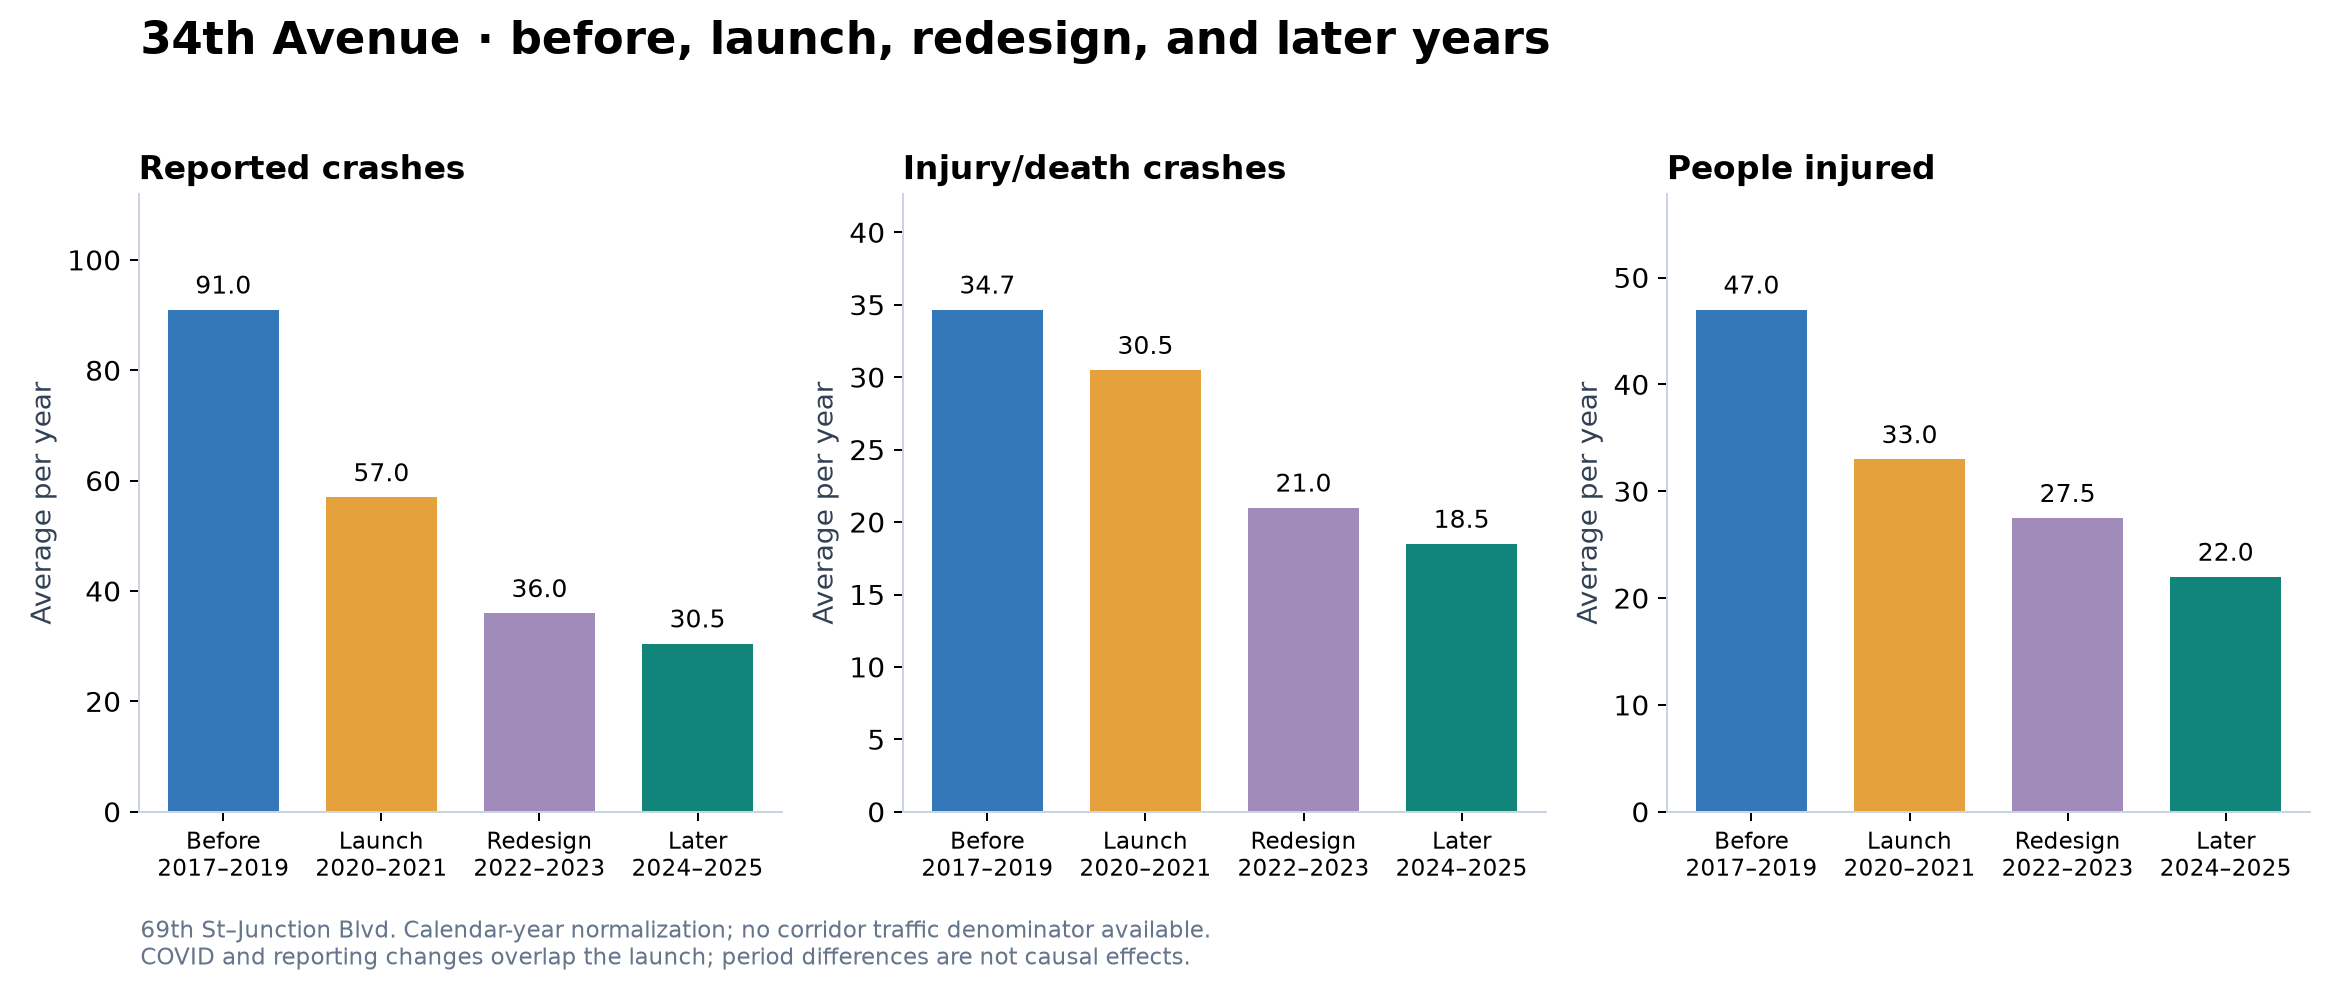

In [10]:
street_periods = [('Before\n2017–2019', 2017, 2019, BLUE), ('Launch\n2020–2021', 2020, 2021, ORANGE),
                  ('Redesign\n2022–2023', 2022, 2023, '#a18bba'), ('Later\n2024–2025', 2024, 2025, TEAL)]
rows = []
for label, start, end, color in street_periods:
    sub = street_y.loc[start:end]
    row = {'period': label.replace('\n', ' '), 'years': len(sub)}
    for metric in ['crashes', 'harm_crashes', 'injured', 'ped_injured', 'cyclist_injured']:
        row[metric + '_per_year'] = sub[metric].sum() / len(sub)
    rows.append(row)
street_rates = pd.DataFrame(rows)
street_rates.to_csv(OUT / 'data/34ave_period_rates.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 5.5))
for ax, metric, title in zip(axes, ['crashes', 'harm_crashes', 'injured'], ['Reported crashes', 'Injury/death crashes', 'People injured']):
    values = street_rates[metric + '_per_year']
    bars = ax.bar(range(4), values, color=[p[3] for p in street_periods], width=.7)
    ax.bar_label(bars, fmt='%.1f', padding=4, fontsize=10)
    ax.set_xticks(range(4), [p[0] for p in street_periods], fontsize=9)
    ax.set_ylabel('Average per year')
    ax.set_title(title, loc='left', fontsize=13)
    ax.set_ylim(0, values.max() * 1.23)
fig.suptitle('34th Avenue · before, launch, redesign, and later years', x=.06, ha='left', fontsize=18, fontweight='bold')
save_graph(fig, '08_34ave_period_comparison', '69th St–Junction Blvd. Calendar-year normalization; no corridor traffic denominator available.\nCOVID and reporting changes overlap the launch; period differences are not causal effects.')

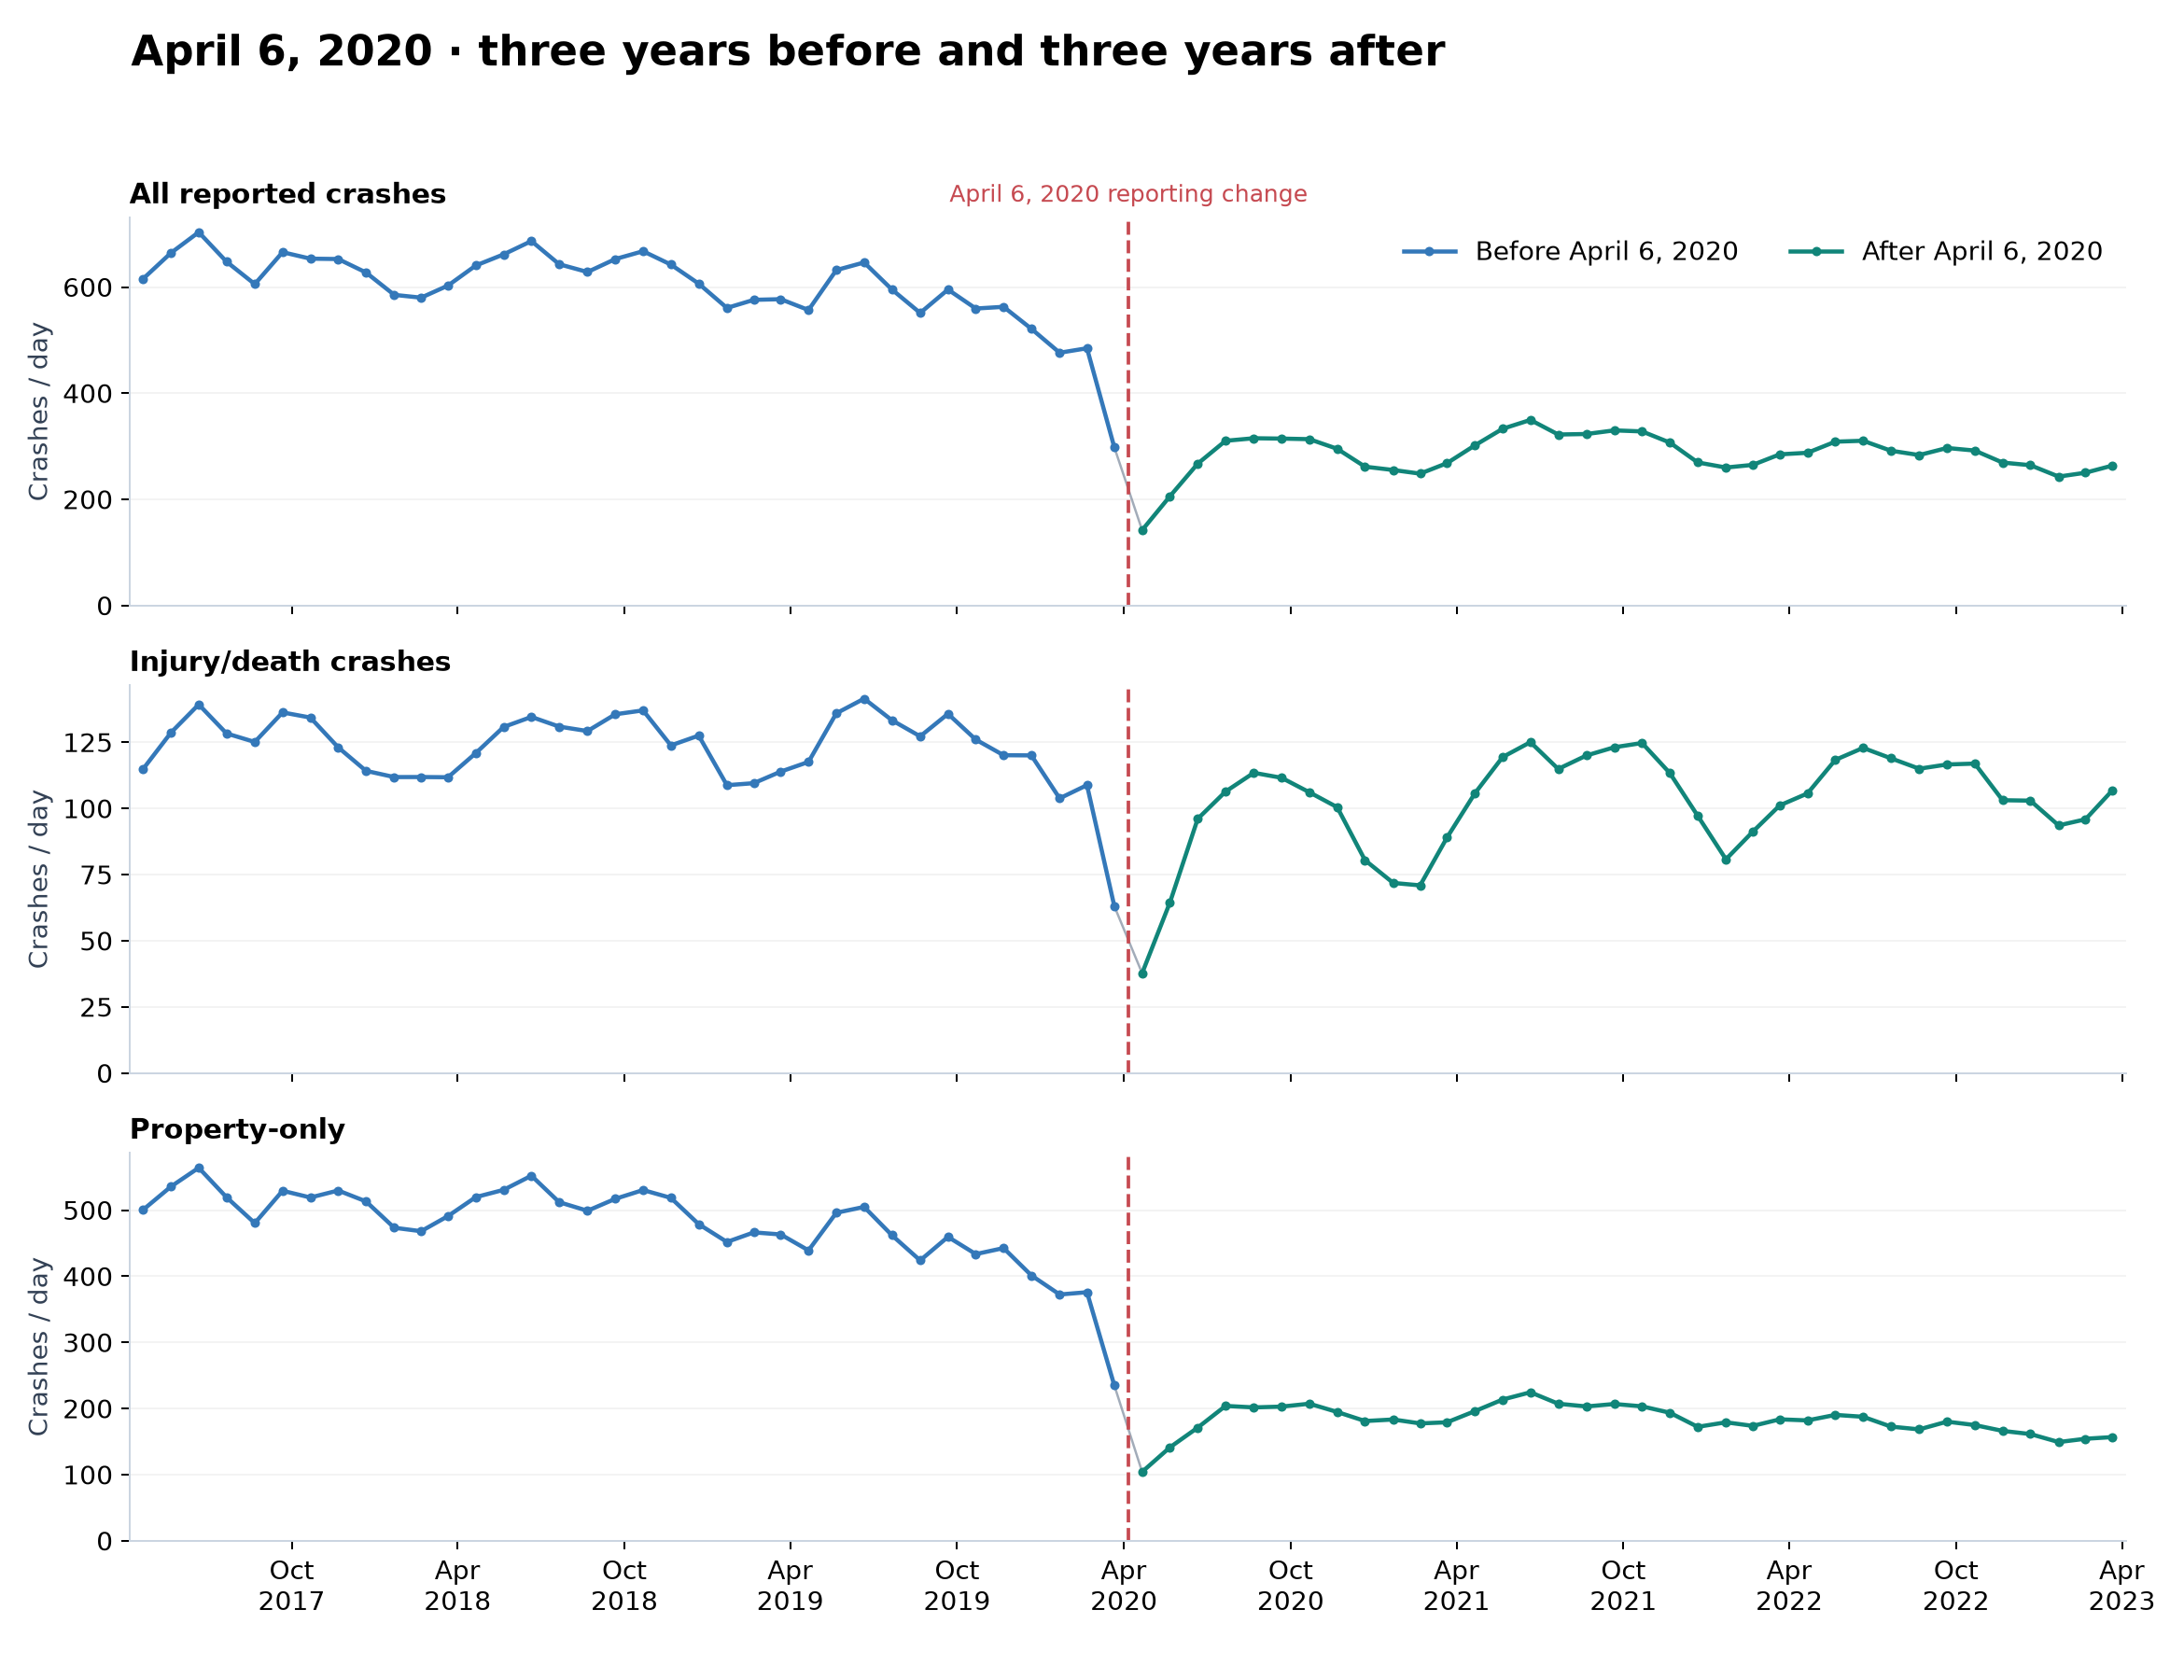

In [11]:
# Compare three full years on either side of the actual reporting-policy date.
april_anchor = pd.Timestamp('2020-04-06')
april_start = april_anchor - pd.DateOffset(years=3)
april_end = april_anchor + pd.DateOffset(years=3)  # exclusive
april_metrics = [('crashes', 'All reported crashes'),
                 ('harm_crashes', 'Injury/death crashes'),
                 ('non_harm_crashes', 'Property-only')]
april_periods = [('Before', april_start, april_anchor), ('After', april_anchor, april_end)]
april_rows, april_month_rows, april_year_rows = [], [], []

def april_period_summary(start, end):
    dates = pd.date_range(start, end - pd.Timedelta(days=1))
    sample = daily.loc[dates]
    assert len(sample) == len(dates)
    assert sample[[metric for metric, _ in april_metrics]].notna().all().all()
    unknown = int((sample.crashes - sample.known_harm).sum())
    return sample, unknown

for period, start, end in april_periods:
    sample, unknown = april_period_summary(start, end)
    for metric, label in april_metrics:
        april_rows.append({'period': period, 'outcome': metric, 'start_date': start.date(),
                           'end_date': (end - pd.Timedelta(days=1)).date(), 'days': len(sample),
                           'count': sample[metric].sum(), 'daily_mean': sample[metric].mean(),
                           'unknown_harm_crashes': unknown})
# Bins run from the 6th through the 5th, so no month straddles the policy date.
for month in range(72):
    start = april_start + pd.DateOffset(months=month)
    end = april_start + pd.DateOffset(months=month + 1)
    sample, unknown = april_period_summary(start, end)
    for metric, label in april_metrics:
        april_month_rows.append({'period': 'Before' if start < april_anchor else 'After',
                                 'outcome': metric, 'start_date': start.date(),
                                 'end_date': (end - pd.Timedelta(days=1)).date(), 'days': len(sample),
                                 'count': sample[metric].sum(), 'daily_mean': sample[metric].mean(),
                                 'unknown_harm_crashes': unknown})
for year in range(6):
    start = april_start + pd.DateOffset(years=year)
    end = april_start + pd.DateOffset(years=year + 1)
    sample, unknown = april_period_summary(start, end)
    for metric, label in april_metrics:
        april_year_rows.append({'period': 'Before' if start < april_anchor else 'After',
                                'outcome': metric, 'start_date': start.date(),
                                'end_date': (end - pd.Timedelta(days=1)).date(), 'days': len(sample),
                                'count': sample[metric].sum(), 'daily_mean': sample[metric].mean(),
                                'unknown_harm_crashes': unknown})
april_comparison = pd.DataFrame(april_rows)
april_monthly = pd.DataFrame(april_month_rows)
april_annual = pd.DataFrame(april_year_rows)
for metric, label in april_metrics:
    mask = april_comparison.outcome.eq(metric)
    before, after = april_comparison.loc[mask, 'daily_mean']
    april_comparison.loc[mask, 'after_vs_before_percent'] = 100 * (after / before - 1) if before else np.nan
    # Independently reconcile the month and year bins to each full period.
    for period in ['Before', 'After']:
        row = april_comparison.loc[mask & april_comparison.period.eq(period)].iloc[0]
        for bins in [april_monthly, april_annual]:
            sub = bins.loc[bins.outcome.eq(metric) & bins.period.eq(period)]
            assert sub['count'].sum() == row['count']
            assert sub.days.sum() == row.days
april_comparison.to_csv(OUT / 'data/april6_three_year_comparison.csv', index=False)
april_monthly.to_csv(OUT / 'data/april6_six_year_monthly_trends.csv', index=False)
april_annual.to_csv(OUT / 'data/april6_six_year_annual_trends.csv', index=False)

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (metric, label) in zip(axes, april_metrics):
    sub = april_monthly.loc[april_monthly.outcome.eq(metric)]
    centers = pd.to_datetime(sub.start_date) + pd.to_timedelta(sub.days / 2, unit='D')
    ax.plot(centers, sub.daily_mean, color=GRAY, lw=1, alpha=.6)
    for period, color in [('Before', BLUE), ('After', TEAL)]:
        mask = sub.period.eq(period)
        ax.plot(centers.loc[mask], sub.loc[mask, 'daily_mean'], 'o-', color=color, ms=3, lw=1.8,
                label=period + ' April 6, 2020')
    ax.axvline(april_anchor, color=RED, ls='--', lw=1.5)
    ax.set_ylabel('Crashes / day')
    ax.set_title(label, loc='left', fontsize=12)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=.15)
axes[0].legend(frameon=False, ncol=2, loc='upper right')
axes[0].text(april_anchor, 1.04, 'April 6, 2020 reporting change', color=RED,
             transform=axes[0].get_xaxis_transform(), fontsize=10, ha='center')
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[4, 10]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
axes[-1].set_xlim(april_start, april_end)
fig.suptitle('April 6, 2020 · three years before and three years after', x=.06, ha='left', fontsize=18, fontweight='bold')
save_graph(fig, '09_april6_six_year_monthly_trends')

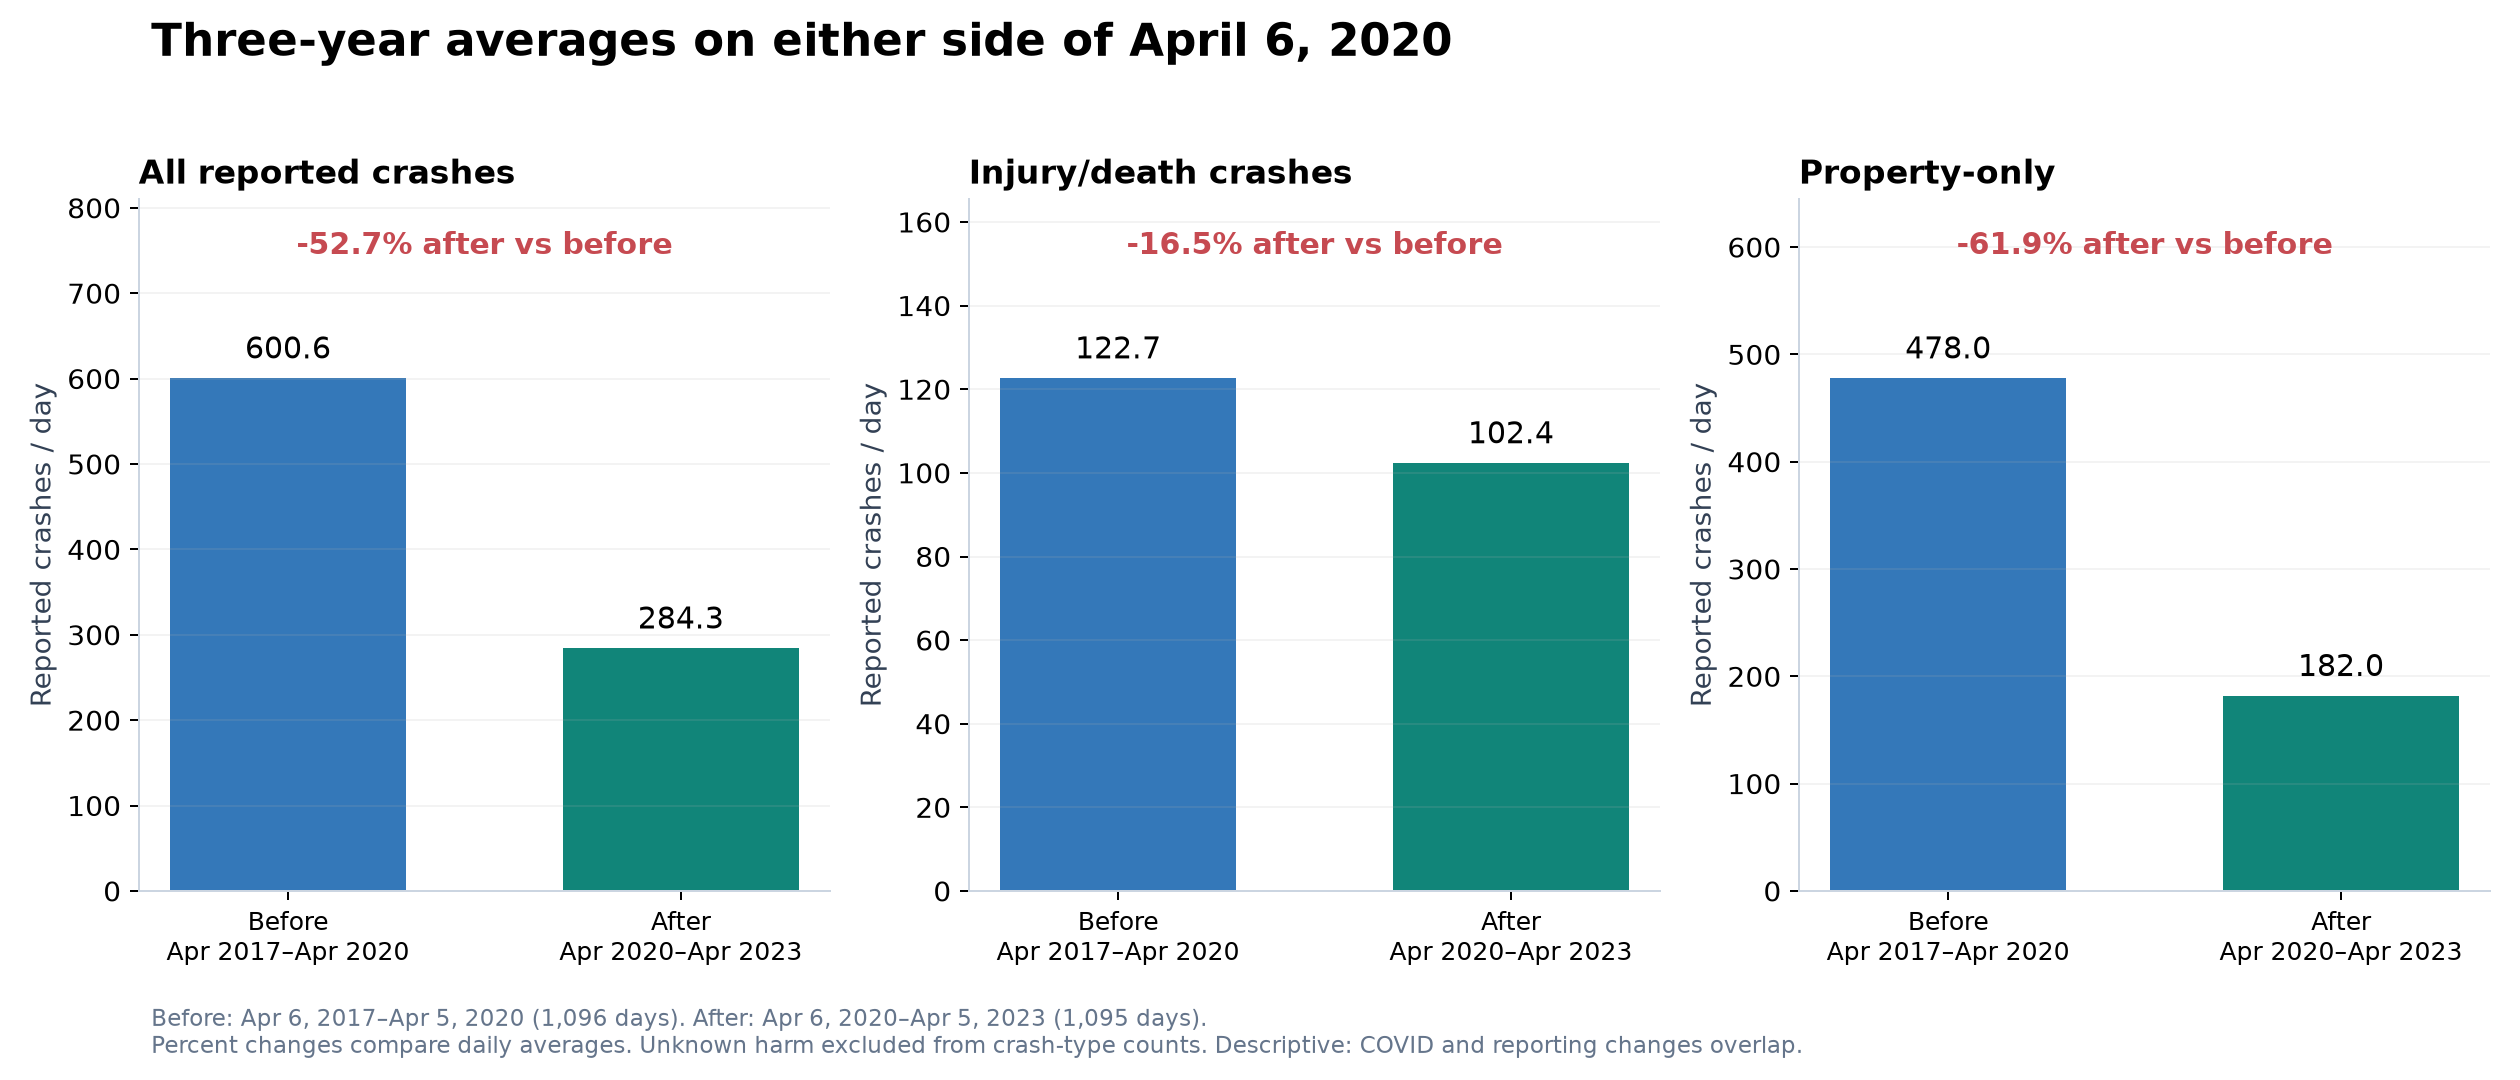

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6))
for ax, (metric, label) in zip(axes, april_metrics):
    sub = april_comparison.loc[april_comparison.outcome.eq(metric)].set_index('period').loc[['Before', 'After']]
    bars = ax.bar(range(2), sub.daily_mean, width=.6, color=[BLUE, TEAL])
    ax.bar_label(bars, fmt='%.1f', padding=5, fontsize=12)
    ax.set_xticks(range(2), ['Before\nApr 2017–Apr 2020', 'After\nApr 2020–Apr 2023'], fontsize=10)
    ax.set_title(label, loc='left', fontsize=13)
    ax.set_ylabel('Reported crashes / day')
    ax.set_ylim(0, sub.daily_mean.max() * 1.35)
    ax.text(.5, .92, f'{sub.after_vs_before_percent.iloc[0]:+.1f}% after vs before',
            ha='center', transform=ax.transAxes, fontsize=12, fontweight='bold', color=RED)
    ax.grid(axis='y', alpha=.15)
fig.suptitle('Three-year averages on either side of April 6, 2020', x=.06, ha='left', fontsize=18, fontweight='bold')
save_graph(fig, '10_april6_three_year_before_after',
           'Before: Apr 6, 2017–Apr 5, 2020 (1,096 days). After: Apr 6, 2020–Apr 5, 2023 (1,095 days).\n'
           'Percent changes compare daily averages. Unknown harm excluded from crash-type counts. Descriptive: COVID and reporting changes overlap.')

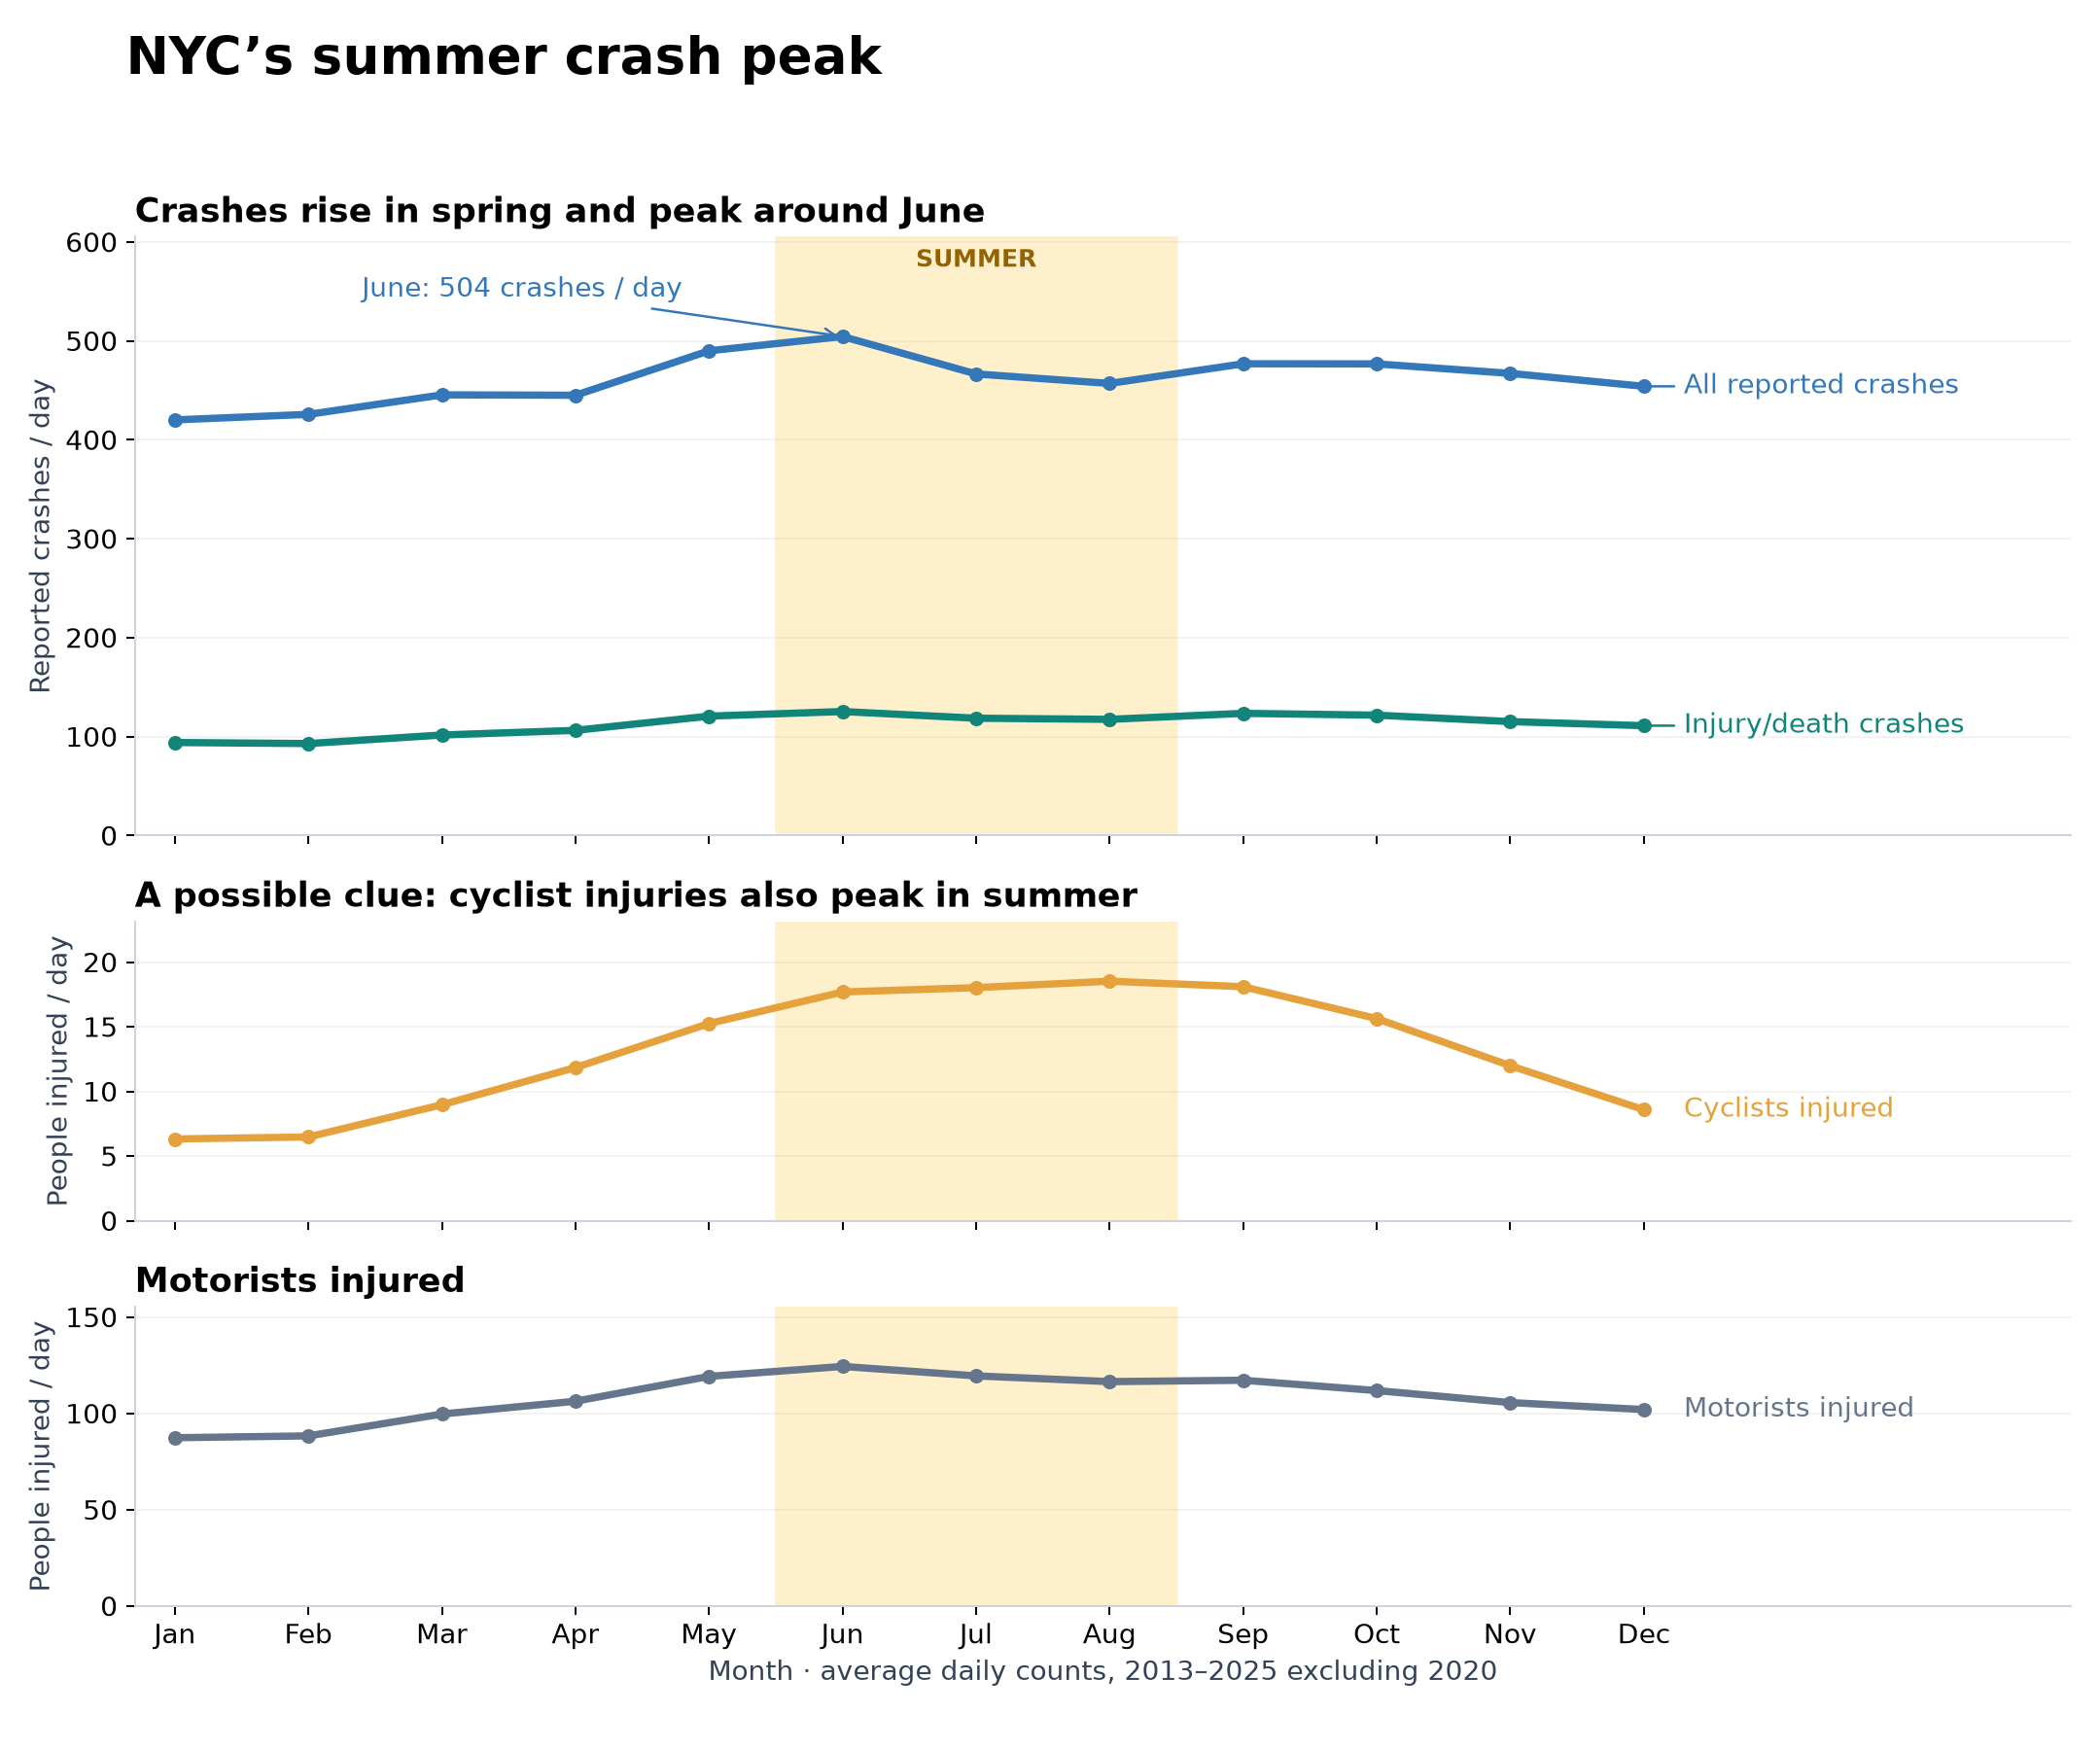

In [13]:
# Actual daily counts account for month length; average each calendar month
# across complete years, with equal weight for every year.
seasonal_months = monthly.loc[(monthly.index.year >= 2013) & (monthly.index.year <= 2025)
                             & (monthly.index.year != 2020)].copy()
seasonal_metrics = ['crashes', 'harm_crashes', 'cyclist_injured', 'motorist_injured']
assert seasonal_months.groupby(seasonal_months.index.year).size().eq(12).all()
seasonal_daily = seasonal_months[seasonal_metrics].div(seasonal_months.calendar_days, axis=0)
seasonal_profile = seasonal_daily.groupby(seasonal_daily.index.month).mean()
seasonal_profile.index.name = 'month'
seasonal_profile.to_csv(OUT / 'data/seasonal_summer_peak.csv')
seasonal_daily.to_csv(OUT / 'data/seasonal_summer_peak_by_year.csv')
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1, 1]})
x = np.arange(1, 13)
for ax in axes:
    ax.axvspan(5.5, 8.5, color='#fff0cc', zorder=0)
    ax.grid(axis='y', alpha=.15)
    ax.set_xlim(.7, 15.2)
axes[0].set_ylabel('Reported crashes / day')
for metric, label, color in [('crashes', 'All reported crashes', BLUE),
                              ('harm_crashes', 'Injury/death crashes', TEAL)]:
    axes[0].plot(x, seasonal_profile[metric], 'o-', color=color, lw=3, ms=5)
    label_y = seasonal_profile.loc[12, metric]
    axes[0].annotate(label, xy=(12, seasonal_profile.loc[12, metric]),
                     xytext=(12.3, label_y), color=color, va='center', fontsize=11,
                     arrowprops={'arrowstyle': '-', 'color': color})
crash_top = seasonal_profile.crashes.max() * 1.2
axes[0].set_ylim(0, crash_top)
axes[0].set_title('Crashes rise in spring and peak around June', loc='left', fontsize=14)
axes[0].text(7, crash_top * .95, 'SUMMER', ha='center', color='#946200', fontsize=10, fontweight='bold')
peak_month = int(seasonal_profile.crashes.idxmax())
axes[0].annotate(f'June: {seasonal_profile.loc[peak_month, "crashes"]:.0f} crashes / day',
                 xy=(peak_month, seasonal_profile.loc[peak_month, 'crashes']),
                 xytext=(2.4, crash_top * .90), color=BLUE, fontsize=11,
                 arrowprops={'arrowstyle': '->', 'color': BLUE})
for ax, metric, label, color in zip(axes[1:], ['cyclist_injured', 'motorist_injured'],
                                   ['Cyclists injured', 'Motorists injured'], [ORANGE, GRAY]):
    ax.plot(x, seasonal_profile[metric], 'o-', color=color, lw=3, ms=5)
    ax.text(12.3, seasonal_profile.loc[12, metric], label, color=color, va='center', fontsize=11)
    ax.set_ylim(0, seasonal_profile[metric].max() * 1.25)
    ax.set_ylabel('People injured / day')
    ax.set_title(label, loc='left', fontsize=14)
axes[1].set_title('A possible clue: cyclist injuries also peak in summer', loc='left', fontsize=14)
axes[-1].set_xticks(x, ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
axes[-1].set_xlabel('Month · average daily counts, 2013–2025 excluding 2020')
fig.suptitle('NYC’s summer crash peak', x=.06, ha='left', fontsize=21, fontweight='bold')
save_graph(fig, '11_seasonal_summer_peak')
(OUT / 'data/seasonal_summer_peak_metadata.json').write_text(json.dumps({
    'years': sorted(set(seasonal_months.index.year.tolist())),
    'excluded_years': {'2012': 'Partial year', '2020': 'Pandemic and reporting transition', '2026': 'Partial year'},
    'method': 'Actual counts divided by calendar days. Monthly profiles average years equally; no yearly indexing. Injury panels use separate labeled scales.',
    'interpretation': 'Cyclist and motorist injuries are related outcomes, not measures of trips or exposure. Warm-weather activity is a hypothesis; this graph cannot identify a cause or separate exposure from risk.',
    'source': SOURCES['crashes'], 'traffic_adjusted': False,
}, indent=2))

In [14]:
audit = {'sources': SOURCES, 'source_accessed': '2026-10-17',
         'notebook_contains_markdown': False, 'graphs': sorted(p.name for p in GRAPHS.glob('*.png')),
         'covid_denominator': 'Sum of mean-site daily sampled traffic on the same dates as outcome counts; outcomes divided by denominator and multiplied by 10,000, without baseline indexing.',
         'covid_no_sample_months_2020': [str(m.date()) for m in mo.index[(mo.index.year == 2020) & mo.sampled_days.eq(0)]],
         'property_only_definition': 'Known zero injured and killed; proxy for property-damage-only reports, not unobserved collisions.',
         '34ave': street_audit,
         'april6_comparison': {'before': ['2017-04-06', '2020-04-05'],
                               'after': ['2020-04-06', '2023-04-05'],
                               'policy_date': '2020-04-06', 'traffic_adjusted': False},
         'inputs_sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [
             ROOT / 'data/processed/daily_policy_panel.csv', ROOT / 'data/processed/monthly_policy_panel.csv',
             ROOT / 'data/processed/daily_crashes_with_traffic_coverage.csv', OUT / 'data/street_centerlines.json']}}
assert len(audit['graphs']) == 11
assert all(len(daily.loc[pd.date_range(start, end)]) == 14 for _, start, end in stages)
(OUT / 'data/validation.json').write_text(json.dumps(audit, indent=2))